# 2. Especificação, estimação, robustezes e extensões

**Oaxaca | 570 municípios | variação da pobreza entre 2010 e 2020**

O roteiro apresenta cada modelo e diagnóstico em um bloco explícito. Os resultados aparecem no console pelos resumos nativos e por impressões identificadas de estatísticas e intervalos. Cada resultado analítico é seguido de sua interpretação em Markdown.

Execute após o notebook 1, com kernel limpo. As entradas são a base tratada e sua procedência. Os 22 CSVs do projeto documentam os resultados e a auditoria. A leitura de pobreza extrema compara SEM e SDM com Queen. As conclusões são associativas e consideram as limitações de identificação e os resultados adversos das especificações.

## 1. Leitura independente e parâmetros

O notebook lê somente o GeoPackage exportado pelo primeiro. Nenhuma variável do outro kernel é necessária. Os controles socioeconômicos são de 2010; altitude é a aproximação geográfica de referência 2020 já discutida.

SciPy fornece distribuições e álgebra linear; statsmodels é usado para White e para diagnósticos robustos da primeira etapa. São mantidos os mesmos pacotes e parâmetros da execução anterior, sem instalação ou configuração automática.

O NumPy organiza as matrizes, o SciPy resolve sistemas e fornece distribuições de referência, e o statsmodels calcula os diagnósticos auxiliares. A linha de saída registra Python e spreg para identificar a versão usada na estimação.

In [1]:
# Importando as rotinas de estimação, diagnóstico e álgebra linear
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import libpysal
import spreg
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_white
from scipy import linalg, stats

# Definindo o corte nominal dos testes e o sistema métrico da vizinhança
ALFA, PERMUTACOES, SEMENTE = .05, 999, 42
CRS_METRICO = 'EPSG:6372'
sns.set_theme(style='whitegrid')
print('Python:', sys.version.split()[0], '| spreg:', spreg.__version__)

Python: 3.14.3 | spreg: 1.9.1


### 1.1 Base, amostras e matrizes

Conferimos as fórmulas e a validade das geometrias ao reabrir a base. Os casos completos são definidos por desfecho, e a KNN usa a mesma amostra da pobreza extrema/Queen. Na base atual, extrema e total têm os mesmos 570 municípios. Se essa igualdade mudar, o fluxo interrompe para que se acrescente a comparação em amostra comum, em vez de alterar a composição silenciosamente.

Reconstruímos os pesos pelos IDs textuais. KNN usa centroides em metros; todas as linhas somam 1 e nenhuma matriz tem ilhas. Essa etapa garante que a linha de W corresponda ao mesmo município em y, X, mapas e resíduos.

A verificação das fórmulas compara a mudança exportada com os níveis originais e o logaritmo com a população censitária. Cada matriz é construída com a mesma sequência de códigos usada para formar y e X. Assim, a linha da matriz e a observação na regressão correspondem ao mesmo município.

In [2]:
# Localizando a raiz do projeto para ler a camada municipal exportada
for pasta in [Path.cwd(), *Path.cwd().parents]:
    if (pasta / 'README.md').is_file() and (pasta / 'data').is_dir():
        raiz = pasta
        break
assert (raiz / 'docs/SPEC.md').is_file()
tabelas, figuras = raiz / 'outputs/tables', raiz / 'outputs/figures'
dados = gpd.read_file(raiz / 'data/processed/oaxaca_analise.gpkg', layer='municipios').sort_values('mun').reset_index(drop=True)
# Conferindo os identificadores e as variáveis derivadas na base reaberta
assert dados['mun'].is_unique and dados.geometry.is_valid.all()
assert np.allclose(dados.delta_pepov, dados.pepov_20 - dados.pepov_10)
assert np.allclose(dados.delta_ppov, dados.ppov_20 - dados.ppov_10)
assert np.allclose(dados.ln_ptot10, np.log(dados.PTOT10))
controles = ['GRAD10', 'p_PIND10', 'p_PHA10', 'ln_ptot10', 'ALTID']
# Selecionando as amostras para comparação
extrema = dados.loc[dados.amostra_extrema.eq(1)].copy().reset_index(drop=True)
total = dados.loc[dados.amostra_total.eq(1)].copy().reset_index(drop=True)
assert extrema.mun.tolist() == total.mun.tolist(), 'Amostras diferentes: acrescentar comparação em amostra comum.'

# Reconstruindo as matrizes na ordem dos municípios da amostra
ids = extrema.mun.tolist()
extrema_metrica = extrema.to_crs(CRS_METRICO)
centros = extrema_metrica.centroid
queen = libpysal.weights.Queen.from_dataframe(extrema, ids=ids)
knn = libpysal.weights.KNN.from_array(np.column_stack([centros.x, centros.y]), k=5, ids=ids)

assert queen.id_order == ids and not queen.islands and np.all(queen.sparse.diagonal() == 0)
# Normalizando as linhas para interpretar a defasagem como média ponderada
queen.transform = 'r'
assert np.allclose(np.asarray(queen.sparse.sum(axis=1)).ravel(), 1)

assert knn.id_order == ids and not knn.islands and np.all(knn.sparse.diagonal() == 0)
# Normalizando as linhas para interpretar a defasagem como média ponderada
knn.transform = 'r'
assert np.allclose(np.asarray(knn.sparse.sum(axis=1)).ravel(), 1)

## 2. Variáveis da regressão

O desfecho é a mudança da pobreza em p.p. A matriz X inclui a taxa inicial correspondente e os cinco controles. O intercepto será acrescentado pelo estimador. Construímos explicitamente os arrays para pobreza extrema e total, ambos com os mesmos 570 municípios.

In [3]:
# Organizando a pobreza inicial e os cinco controles de cada desfecho
nomes_extrema = ['pepov_10', *controles]
nomes_total = ['ppov_10', *controles]
y_extrema = extrema[['delta_pepov']].to_numpy()
x_extrema = extrema[nomes_extrema].to_numpy()
y_total = total[['delta_ppov']].to_numpy()
x_total = total[nomes_total].to_numpy()

# Preparando os registros que serão consolidados nos CSVs
lista_coeficientes_mqo = []
lista_coeficientes_espaciais = []
lista_diagnosticos_mqo = []
lista_trajetorias = []
instrumentos = []
lista_impactos = []
lista_residuos = []
lista_diagnosticos = []
linhas_comparacao = []
h4 = []
coeficientes_regimes = []

### 2. MQO — Pobreza extrema / Queen

O resumo nativo apresenta o coeficiente de cada regressor, sua incerteza, a medida de ajuste e os testes calculados pelo spreg. A covariância White acomoda heterocedasticidade na inferência dos coeficientes. A seleção espacial será avaliada após os diagnósticos.

In [4]:
# Estimando MQO com covariância White para Pobreza extrema / Queen
mqo_extrema_queen = spreg.OLS(y_extrema, x_extrema, w=queen, robust='white', spat_diag=True, moran=True,
    name_y='delta_pobreza', name_x=nomes_extrema, name_w='extrema_queen', vm=True)
print(mqo_extrema_queen.summary)
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = mqo_extrema_queen.betas.ravel()
se = np.sqrt(np.diag(mqo_extrema_queen.vm))
lista_coeficientes_mqo.append(pd.DataFrame({'analise': 'extrema_queen', 'modelo': 'MQO',
    'variavel': mqo_extrema_queen.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': True, 'covariancia': 'White',
    'unidade_y': 'p.p. de variação 2020–2010'}))

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :extrema_queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :           7
S.D. dependent var  :     14.0584                Degrees of Freedom    :         563
R-squared           :      0.5801
Adjusted R-squared  :      0.5757
Sum squared residual:     47216.7                F-statistic           :    129.6517
Sigma-square        :      83.866                Prob(F-statistic)     :  1.089e-102
S.E. of regression  :       9.158                Log likelihood        :   -2067.602
Sigma-square ML     :      82.836                Akaike info criterion :    4149.204
S.E of regression ML:      9.1014                Schwarz criterion     :    4179.623

White Standard 

**Leitura do MQO.** O coeficiente inicial é -0.4942, com intervalo de 95% de -0.5560 a -0.4324. O sinal negativo associa maior pobreza inicial a uma mudança mais negativa, dadas as condições observadas. Esta é a referência inicial para comparar as especificações espaciais. A covariância dos coeficientes e os testes de especificação têm pressupostos próprios.

### 2. Diagnósticos do MQO — Pobreza extrema / Queen

Imprimimos os diagnósticos complementares ao resumo. O teste White usa X padronizado apenas na regressão auxiliar. A regressão principal conserva os regressores nas unidades originais. O Moran residual utiliza os momentos próprios da regressão. Os p-valores devem ser lidos em relação a cada hipótese nula.

In [5]:
# Reunindo os testes espaciais nas hipóteses documentadas
lm = np.asarray([mqo_extrema_queen.lm_wx, mqo_extrema_queen.lm_spdurbin, mqo_extrema_queen.rlm_wx, mqo_extrema_queen.rlm_durlag, mqo_extrema_queen.lm_lag, mqo_extrema_queen.lm_error, mqo_extrema_queen.rlm_lag, mqo_extrema_queen.rlm_error])
diagnosticos = pd.DataFrame({'analise': 'extrema_queen', 'teste': ['lm_wx', 'lm_spdurbin', 'rlm_wx', 'rlm_durlag', 'lm_lag', 'lm_error', 'rlm_lag', 'rlm_error'],
    'h0': ['theta=0: sem WX', 'rho=theta=0', 'theta=0, ajustado ao lag', 'rho=0, ajustado a WX', 'rho=0', 'lambda=0', 'rho=0, ajustado ao erro', 'lambda=0, ajustado ao lag'], 'estatistica': lm[:, 0], 'p_valor': lm[:, 1]})

# Conferindo normalidade, heterocedasticidade e condicionamento dos regressores
jb = mqo_extrema_queen.jarque_bera
bp = mqo_extrema_queen.breusch_pagan
kb = mqo_extrema_queen.koenker_bassett
x_auxiliar = np.asarray(mqo_extrema_queen.x)[:, 1:]
x_padrao = (x_auxiliar - x_auxiliar.mean(axis=0)) / x_auxiliar.std(axis=0)
white, p_white, _, _ = het_white(mqo_extrema_queen.u.ravel(), sm.add_constant(x_padrao))
i_moran, z_moran, p_moran = mqo_extrema_queen.moran_res
adicionais = pd.DataFrame([
    {'analise': 'extrema_queen', 'teste': 'jarque_bera', 'estatistica': jb['jb'], 'p_valor': jb['pvalue']},
    {'analise': 'extrema_queen', 'teste': 'breusch_pagan', 'estatistica': bp['bp'], 'p_valor': bp['pvalue']},
    {'analise': 'extrema_queen', 'teste': 'koenker_bassett', 'estatistica': kb['kb'], 'p_valor': kb['pvalue']},
    {'analise': 'extrema_queen', 'teste': 'white', 'estatistica': white, 'p_valor': p_white},
    {'analise': 'extrema_queen', 'teste': 'moran_residual', 'estatistica': z_moran,
      'I_residual': i_moran, 'p_valor': p_moran},
    {'analise': 'extrema_queen', 'teste': 'numero_condicao', 'estatistica': mqo_extrema_queen.mulColli, 'p_valor': np.nan}])
lista_diagnosticos_mqo.extend([diagnosticos, adicionais])
print('Número de condição:', mqo_extrema_queen.mulColli)
print('Jarque–Bera e p:', jb['jb'], jb['pvalue'])
print('Breusch–Pagan e p:', bp['bp'], bp['pvalue'])
print('Koenker–Bassett e p:', kb['kb'], kb['pvalue'])
print('White e p:', white, p_white)
print('Moran residual, z e p:', i_moran, z_moran, p_moran)

Número de condição: 32.28990938995528
Jarque–Bera e p: 25.119071055015926 3.511260291559038e-06
Breusch–Pagan e p: 88.26879842271421 6.932221568965016e-17
Koenker–Bassett e p: 61.765986064890825 1.9688006248307207e-11
White e p: 94.16915289762443 2.2859745214300377e-09
Moran residual, z e p: 0.13950207819365704 5.737808610243561 9.590940939720904e-09


**Leitura dos diagnósticos.** O número de condição é 32.29. Os p-valores de JB (3.511e-06), BP (6.932e-17), KB (1.969e-11) e White (2.286e-09) permitem avaliar a normalidade e a variância residual sob suas hipóteses. O Moran residual tem p = 9.591e-09, indicando associação espacial remanescente a ser considerada na especificação. As covariâncias White dos coeficientes convivem com os pressupostos dos testes LM e Moran.

### 3. Seleção STGE-Pre — Pobreza extrema / Queen

Começamos pelo teste LM-WX. Havendo rejeição, examinamos o conjunto Durbin e os testes robustos de WX e lag. Sem rejeição de WX, a revisão passaria aos LM lag/erro clássicos e seus robustos. O código verifica explicitamente a trajetória observada nesta base e interrompe a execução se ela mudar.

In [6]:
# Examinando a sequência STGE-Pre para Pobreza extrema / Queen
print('LM-WX e p:', mqo_extrema_queen.lm_wx)
print('LM-Durbin conjunto e p:', mqo_extrema_queen.lm_spdurbin)
print('LM-WX robusto ao lag e p:', mqo_extrema_queen.rlm_wx)
print('LM-lag robusto a WX e p:', mqo_extrema_queen.rlm_durlag)
print('LM-lag e LM-erro clássicos:', mqo_extrema_queen.lm_lag, mqo_extrema_queen.lm_error)
print('Robustos lag e erro clássicos:', mqo_extrema_queen.rlm_lag, mqo_extrema_queen.rlm_error)

# Interrompendo a estimação quando os testes deixam de sustentar este caminho
assert mqo_extrema_queen.lm_wx[1] < ALFA, 'Ramo mudou: revisar os testes lag/erro antes de estimar'
assert mqo_extrema_queen.lm_spdurbin[1] < ALFA, 'Teste conjunto não rejeitado: revisar a especificação'
assert mqo_extrema_queen.rlm_wx[1] < ALFA and mqo_extrema_queen.rlm_durlag[1] < ALFA, 'Indicação mudou: revisar SDM, SLX e SAR'
lista_trajetorias.append({'analise': 'extrema_queen', 'ramo': 'Durbin', 'indicacao': 'SDM',
    'p_lm_wx': mqo_extrema_queen.lm_wx[1], 'p_conjunto': mqo_extrema_queen.lm_spdurbin[1],
    'p_robusto_wx': mqo_extrema_queen.rlm_wx[1], 'p_robusto_lag': mqo_extrema_queen.rlm_durlag[1]})
print('Trajetória conferida: ramo Durbin, indicação SDM')

LM-WX e p: (np.float64(25.04523493713768), np.float64(0.0003349318045478763))
LM-Durbin conjunto e p: (np.float64(54.0226443904724), np.float64(2.3277604964332704e-09))
LM-WX robusto ao lag e p: (np.float64(35.81088004518166), np.float64(3.0000133419820793e-06))
LM-lag robusto a WX e p: (np.float64(28.977409453334722), np.float64(7.322729859383194e-08))
LM-lag e LM-erro clássicos: (np.float64(18.211764345290742), np.float64(1.976541745326305e-05)) (np.float64(28.977409453529237), np.float64(7.32272985864789e-08))
Robustos lag e erro clássicos: (np.float64(0.240546297138633), np.float64(0.6238118283609612)) (np.float64(11.00619140537713), np.float64(0.0009080804404325134))
Trajetória conferida: ramo Durbin, indicação SDM


**Leitura da seleção.** O LM-WX tem p = 0.0003349, abrindo o ramo Durbin. O conjunto é rejeitado, e os testes robustos de WX (p = 3e-06) e lag (p = 7.323e-08) também rejeitam a 5%. Essa combinação indica estimar o SDM. A indicação será confrontada com admissibilidade, instrumentos e diagnósticos posteriores.

### 2. MQO — Pobreza extrema / KNN-5

O resumo nativo apresenta o coeficiente de cada regressor, sua incerteza, a medida de ajuste e os testes calculados pelo spreg. A covariância White acomoda heterocedasticidade na inferência dos coeficientes. A seleção espacial será avaliada após os diagnósticos.

In [7]:
# Estimando MQO com covariância White para Pobreza extrema / KNN-5
mqo_extrema_knn5 = spreg.OLS(y_extrema, x_extrema, w=knn, robust='white', spat_diag=True, moran=True,
    name_y='delta_pobreza', name_x=nomes_extrema, name_w='extrema_knn5', vm=True)
print(mqo_extrema_knn5.summary)
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = mqo_extrema_knn5.betas.ravel()
se = np.sqrt(np.diag(mqo_extrema_knn5.vm))
lista_coeficientes_mqo.append(pd.DataFrame({'analise': 'extrema_knn5', 'modelo': 'MQO',
    'variavel': mqo_extrema_knn5.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': True, 'covariancia': 'White',
    'unidade_y': 'p.p. de variação 2020–2010'}))

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :extrema_knn5
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :           7
S.D. dependent var  :     14.0584                Degrees of Freedom    :         563
R-squared           :      0.5801
Adjusted R-squared  :      0.5757
Sum squared residual:     47216.7                F-statistic           :    129.6517
Sigma-square        :      83.866                Prob(F-statistic)     :  1.089e-102
S.E. of regression  :       9.158                Log likelihood        :   -2067.602
Sigma-square ML     :      82.836                Akaike info criterion :    4149.204
S.E of regression ML:      9.1014                Schwarz criterion     :    4179.623

White Standard E

**Leitura do MQO.** O coeficiente inicial é -0.4942, com intervalo de 95% de -0.5560 a -0.4324. O sinal negativo associa maior pobreza inicial a uma mudança mais negativa, dadas as condições observadas. Esta é a referência inicial para comparar as especificações espaciais. A covariância dos coeficientes e os testes de especificação têm pressupostos próprios.

### 2. Diagnósticos do MQO — Pobreza extrema / KNN-5

Imprimimos os diagnósticos complementares ao resumo. O teste White usa X padronizado apenas na regressão auxiliar. A regressão principal conserva os regressores nas unidades originais. O Moran residual utiliza os momentos próprios da regressão. Os p-valores devem ser lidos em relação a cada hipótese nula.

In [8]:
# Reunindo os testes espaciais nas hipóteses documentadas
lm = np.asarray([mqo_extrema_knn5.lm_wx, mqo_extrema_knn5.lm_spdurbin, mqo_extrema_knn5.rlm_wx, mqo_extrema_knn5.rlm_durlag, mqo_extrema_knn5.lm_lag, mqo_extrema_knn5.lm_error, mqo_extrema_knn5.rlm_lag, mqo_extrema_knn5.rlm_error])
diagnosticos = pd.DataFrame({'analise': 'extrema_knn5', 'teste': ['lm_wx', 'lm_spdurbin', 'rlm_wx', 'rlm_durlag', 'lm_lag', 'lm_error', 'rlm_lag', 'rlm_error'],
    'h0': ['theta=0: sem WX', 'rho=theta=0', 'theta=0, ajustado ao lag', 'rho=0, ajustado a WX', 'rho=0', 'lambda=0', 'rho=0, ajustado ao erro', 'lambda=0, ajustado ao lag'], 'estatistica': lm[:, 0], 'p_valor': lm[:, 1]})

# Conferindo normalidade, heterocedasticidade e condicionamento dos regressores
jb = mqo_extrema_knn5.jarque_bera
bp = mqo_extrema_knn5.breusch_pagan
kb = mqo_extrema_knn5.koenker_bassett
x_auxiliar = np.asarray(mqo_extrema_knn5.x)[:, 1:]
x_padrao = (x_auxiliar - x_auxiliar.mean(axis=0)) / x_auxiliar.std(axis=0)
white, p_white, _, _ = het_white(mqo_extrema_knn5.u.ravel(), sm.add_constant(x_padrao))
i_moran, z_moran, p_moran = mqo_extrema_knn5.moran_res
adicionais = pd.DataFrame([
    {'analise': 'extrema_knn5', 'teste': 'jarque_bera', 'estatistica': jb['jb'], 'p_valor': jb['pvalue']},
    {'analise': 'extrema_knn5', 'teste': 'breusch_pagan', 'estatistica': bp['bp'], 'p_valor': bp['pvalue']},
    {'analise': 'extrema_knn5', 'teste': 'koenker_bassett', 'estatistica': kb['kb'], 'p_valor': kb['pvalue']},
    {'analise': 'extrema_knn5', 'teste': 'white', 'estatistica': white, 'p_valor': p_white},
    {'analise': 'extrema_knn5', 'teste': 'moran_residual', 'estatistica': z_moran,
      'I_residual': i_moran, 'p_valor': p_moran},
    {'analise': 'extrema_knn5', 'teste': 'numero_condicao', 'estatistica': mqo_extrema_knn5.mulColli, 'p_valor': np.nan}])
lista_diagnosticos_mqo.extend([diagnosticos, adicionais])
print('Número de condição:', mqo_extrema_knn5.mulColli)
print('Jarque–Bera e p:', jb['jb'], jb['pvalue'])
print('Breusch–Pagan e p:', bp['bp'], bp['pvalue'])
print('Koenker–Bassett e p:', kb['kb'], kb['pvalue'])
print('White e p:', white, p_white)
print('Moran residual, z e p:', i_moran, z_moran, p_moran)

Número de condição: 32.28990938995528
Jarque–Bera e p: 25.119071055015926 3.511260291559038e-06
Breusch–Pagan e p: 88.26879842271421 6.932221568965016e-17
Koenker–Bassett e p: 61.765986064890825 1.9688006248307207e-11
White e p: 94.16915289762443 2.2859745214300377e-09
Moran residual, z e p: 0.13184852989497223 5.695038298195387 1.2334423073585447e-08


**Leitura dos diagnósticos.** O número de condição é 32.29. Os p-valores de JB (3.511e-06), BP (6.932e-17), KB (1.969e-11) e White (2.286e-09) permitem avaliar a normalidade e a variância residual sob suas hipóteses. O Moran residual tem p = 1.233e-08, indicando associação espacial remanescente a ser considerada na especificação. As covariâncias White dos coeficientes convivem com os pressupostos dos testes LM e Moran.

### 3. Seleção STGE-Pre — Pobreza extrema / KNN-5

Começamos pelo teste LM-WX. Havendo rejeição, examinamos o conjunto Durbin e os testes robustos de WX e lag. Sem rejeição de WX, a revisão passaria aos LM lag/erro clássicos e seus robustos. O código verifica explicitamente a trajetória observada nesta base e interrompe a execução se ela mudar.

In [9]:
# Examinando a sequência STGE-Pre para Pobreza extrema / KNN-5
print('LM-WX e p:', mqo_extrema_knn5.lm_wx)
print('LM-Durbin conjunto e p:', mqo_extrema_knn5.lm_spdurbin)
print('LM-WX robusto ao lag e p:', mqo_extrema_knn5.rlm_wx)
print('LM-lag robusto a WX e p:', mqo_extrema_knn5.rlm_durlag)
print('LM-lag e LM-erro clássicos:', mqo_extrema_knn5.lm_lag, mqo_extrema_knn5.lm_error)
print('Robustos lag e erro clássicos:', mqo_extrema_knn5.rlm_lag, mqo_extrema_knn5.rlm_error)

# Interrompendo a estimação quando os testes deixam de sustentar este caminho
assert mqo_extrema_knn5.lm_wx[1] < ALFA, 'Ramo mudou: revisar os testes lag/erro antes de estimar'
assert mqo_extrema_knn5.lm_spdurbin[1] < ALFA, 'Teste conjunto não rejeitado: revisar a especificação'
assert mqo_extrema_knn5.rlm_wx[1] < ALFA and mqo_extrema_knn5.rlm_durlag[1] < ALFA, 'Indicação mudou: revisar SDM, SLX e SAR'
lista_trajetorias.append({'analise': 'extrema_knn5', 'ramo': 'Durbin', 'indicacao': 'SDM',
    'p_lm_wx': mqo_extrema_knn5.lm_wx[1], 'p_conjunto': mqo_extrema_knn5.lm_spdurbin[1],
    'p_robusto_wx': mqo_extrema_knn5.rlm_wx[1], 'p_robusto_lag': mqo_extrema_knn5.rlm_durlag[1]})
print('Trajetória conferida: ramo Durbin, indicação SDM')

LM-WX e p: (np.float64(30.495773314133725), np.float64(3.163244164800908e-05))
LM-Durbin conjunto e p: (np.float64(58.62362649144121), np.float64(2.840466996766671e-10))
LM-WX robusto ao lag e p: (np.float64(43.538287539780384), np.float64(9.126017258564586e-08))
LM-lag robusto a WX e p: (np.float64(28.127853177307482), np.float64(1.1355972152912882e-07))
LM-lag e LM-erro clássicos: (np.float64(15.08533895166082), np.float64(0.00010275827863847893)) (np.float64(28.12785317750349), np.float64(1.135597215176282e-07))
Robustos lag e erro clássicos: (np.float64(0.07726792428080612), np.float64(0.7810345549210067)) (np.float64(13.119782150123479), np.float64(0.0002921940092411313))
Trajetória conferida: ramo Durbin, indicação SDM


**Leitura da seleção.** O LM-WX tem p = 3.163e-05, abrindo o ramo Durbin. O conjunto é rejeitado, e os testes robustos de WX (p = 9.126e-08) e lag (p = 1.136e-07) também rejeitam a 5%. Essa combinação indica estimar o SDM. A indicação será confrontada com admissibilidade, instrumentos e diagnósticos posteriores.

### 2. MQO — Pobreza total / Queen

O resumo nativo apresenta o coeficiente de cada regressor, sua incerteza, a medida de ajuste e os testes calculados pelo spreg. A covariância White acomoda heterocedasticidade na inferência dos coeficientes. A seleção espacial será avaliada após os diagnósticos.

In [10]:
# Estimando MQO com covariância White para Pobreza total / Queen
mqo_total_queen = spreg.OLS(y_total, x_total, w=queen, robust='white', spat_diag=True, moran=True,
    name_y='delta_pobreza', name_x=nomes_total, name_w='total_queen', vm=True)
print(mqo_total_queen.summary)
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = mqo_total_queen.betas.ravel()
se = np.sqrt(np.diag(mqo_total_queen.vm))
lista_coeficientes_mqo.append(pd.DataFrame({'analise': 'total_queen', 'modelo': 'MQO',
    'variavel': mqo_total_queen.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': True, 'covariancia': 'White',
    'unidade_y': 'p.p. de variação 2020–2010'}))

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      : total_queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :     -4.7523                Number of Variables   :           7
S.D. dependent var  :      8.1530                Degrees of Freedom    :         563
R-squared           :      0.2468
Adjusted R-squared  :      0.2388
Sum squared residual:       28488                F-statistic           :     30.7462
Sigma-square        :      50.600                Prob(F-statistic)     :   5.584e-32
S.E. of regression  :       7.113                Log likelihood        :   -1923.602
Sigma-square ML     :      49.979                Akaike info criterion :    3861.204
S.E of regression ML:      7.0696                Schwarz criterion     :    3891.623

White Standard E

**Leitura do MQO.** O coeficiente inicial é -0.1992, com intervalo de 95% de -0.3471 a -0.0513. O sinal negativo associa maior pobreza inicial a uma mudança mais negativa, dadas as condições observadas. Esta é a referência inicial para comparar as especificações espaciais. A covariância dos coeficientes e os testes de especificação têm pressupostos próprios.

### 2. Diagnósticos do MQO — Pobreza total / Queen

Imprimimos os diagnósticos complementares ao resumo. O teste White usa X padronizado apenas na regressão auxiliar. A regressão principal conserva os regressores nas unidades originais. O Moran residual utiliza os momentos próprios da regressão. Os p-valores devem ser lidos em relação a cada hipótese nula.

In [11]:
# Reunindo os testes espaciais nas hipóteses documentadas
lm = np.asarray([mqo_total_queen.lm_wx, mqo_total_queen.lm_spdurbin, mqo_total_queen.rlm_wx, mqo_total_queen.rlm_durlag, mqo_total_queen.lm_lag, mqo_total_queen.lm_error, mqo_total_queen.rlm_lag, mqo_total_queen.rlm_error])
diagnosticos = pd.DataFrame({'analise': 'total_queen', 'teste': ['lm_wx', 'lm_spdurbin', 'rlm_wx', 'rlm_durlag', 'lm_lag', 'lm_error', 'rlm_lag', 'rlm_error'],
    'h0': ['theta=0: sem WX', 'rho=theta=0', 'theta=0, ajustado ao lag', 'rho=0, ajustado a WX', 'rho=0', 'lambda=0', 'rho=0, ajustado ao erro', 'lambda=0, ajustado ao lag'], 'estatistica': lm[:, 0], 'p_valor': lm[:, 1]})

# Conferindo normalidade, heterocedasticidade e condicionamento dos regressores
jb = mqo_total_queen.jarque_bera
bp = mqo_total_queen.breusch_pagan
kb = mqo_total_queen.koenker_bassett
x_auxiliar = np.asarray(mqo_total_queen.x)[:, 1:]
x_padrao = (x_auxiliar - x_auxiliar.mean(axis=0)) / x_auxiliar.std(axis=0)
white, p_white, _, _ = het_white(mqo_total_queen.u.ravel(), sm.add_constant(x_padrao))
i_moran, z_moran, p_moran = mqo_total_queen.moran_res
adicionais = pd.DataFrame([
    {'analise': 'total_queen', 'teste': 'jarque_bera', 'estatistica': jb['jb'], 'p_valor': jb['pvalue']},
    {'analise': 'total_queen', 'teste': 'breusch_pagan', 'estatistica': bp['bp'], 'p_valor': bp['pvalue']},
    {'analise': 'total_queen', 'teste': 'koenker_bassett', 'estatistica': kb['kb'], 'p_valor': kb['pvalue']},
    {'analise': 'total_queen', 'teste': 'white', 'estatistica': white, 'p_valor': p_white},
    {'analise': 'total_queen', 'teste': 'moran_residual', 'estatistica': z_moran,
      'I_residual': i_moran, 'p_valor': p_moran},
    {'analise': 'total_queen', 'teste': 'numero_condicao', 'estatistica': mqo_total_queen.mulColli, 'p_valor': np.nan}])
lista_diagnosticos_mqo.extend([diagnosticos, adicionais])
print('Número de condição:', mqo_total_queen.mulColli)
print('Jarque–Bera e p:', jb['jb'], jb['pvalue'])
print('Breusch–Pagan e p:', bp['bp'], bp['pvalue'])
print('Koenker–Bassett e p:', kb['kb'], kb['pvalue'])
print('White e p:', white, p_white)
print('Moran residual, z e p:', i_moran, z_moran, p_moran)

Número de condição: 53.84925435184388
Jarque–Bera e p: 442.7633902802873 7.163931197849773e-97
Breusch–Pagan e p: 182.31390574561615 1.0942479227467122e-36
Koenker–Bassett e p: 57.71765543818596 1.307292374447019e-10
White e p: 249.39823442093507 7.15271905417874e-38
Moran residual, z e p: 0.09586389500602033 4.022771596024378 5.751726860692433e-05


**Leitura dos diagnósticos.** O número de condição é 53.85. Os p-valores de JB (7.164e-97), BP (1.094e-36), KB (1.307e-10) e White (7.153e-38) permitem avaliar a normalidade e a variância residual sob suas hipóteses. O Moran residual tem p = 5.752e-05, indicando associação espacial remanescente a ser considerada na especificação. As covariâncias White dos coeficientes convivem com os pressupostos dos testes LM e Moran.

### 3. Seleção STGE-Pre — Pobreza total / Queen

Começamos pelo teste LM-WX. Havendo rejeição, examinamos o conjunto Durbin e os testes robustos de WX e lag. Sem rejeição de WX, a revisão passaria aos LM lag/erro clássicos e seus robustos. O código verifica explicitamente a trajetória observada nesta base e interrompe a execução se ela mudar.

In [12]:
# Examinando a sequência STGE-Pre para Pobreza total / Queen
print('LM-WX e p:', mqo_total_queen.lm_wx)
print('LM-Durbin conjunto e p:', mqo_total_queen.lm_spdurbin)
print('LM-WX robusto ao lag e p:', mqo_total_queen.rlm_wx)
print('LM-lag robusto a WX e p:', mqo_total_queen.rlm_durlag)
print('LM-lag e LM-erro clássicos:', mqo_total_queen.lm_lag, mqo_total_queen.lm_error)
print('Robustos lag e erro clássicos:', mqo_total_queen.rlm_lag, mqo_total_queen.rlm_error)

# Interrompendo a estimação quando os testes deixam de sustentar este caminho
assert mqo_total_queen.lm_wx[1] < ALFA, 'Ramo mudou: revisar os testes lag/erro antes de estimar'
assert mqo_total_queen.lm_spdurbin[1] < ALFA, 'Teste conjunto não rejeitado: revisar a especificação'
assert mqo_total_queen.rlm_wx[1] < ALFA and mqo_total_queen.rlm_durlag[1] < ALFA, 'Indicação mudou: revisar SDM, SLX e SAR'
lista_trajetorias.append({'analise': 'total_queen', 'ramo': 'Durbin', 'indicacao': 'SDM',
    'p_lm_wx': mqo_total_queen.lm_wx[1], 'p_conjunto': mqo_total_queen.lm_spdurbin[1],
    'p_robusto_wx': mqo_total_queen.rlm_wx[1], 'p_robusto_lag': mqo_total_queen.rlm_durlag[1]})
print('Trajetória conferida: ramo Durbin, indicação SDM')

LM-WX e p: (np.float64(43.166709611297826), np.float64(1.0810996771189112e-07))
LM-Durbin conjunto e p: (np.float64(56.85056083951007), np.float64(6.400778124855678e-10))
LM-WX robusto ao lag e p: (np.float64(49.27056015976065), np.float64(6.5817335198884255e-09))
LM-lag robusto a WX e p: (np.float64(13.68385122821224), np.float64(0.00021630654532359575))
LM-lag e LM-erro clássicos: (np.float64(7.580000679749416), np.float64(0.005901941800088371)) (np.float64(13.683851228819234), np.float64(0.00021630654525367978))
Robustos lag e erro clássicos: (np.float64(2.2954383090035604), np.float64(0.12975457739014404)) (np.float64(8.399288858073376), np.float64(0.0037536782706823497))
Trajetória conferida: ramo Durbin, indicação SDM


**Leitura da seleção.** O LM-WX tem p = 1.081e-07, abrindo o ramo Durbin. O conjunto é rejeitado, e os testes robustos de WX (p = 6.582e-09) e lag (p = 0.0002163) também rejeitam a 5%. Essa combinação indica estimar o SDM. A indicação será confrontada com admissibilidade, instrumentos e diagnósticos posteriores.

### 3. Registro do ponto de partida

Gravamos os coeficientes dos três MQO, seus diagnósticos e as trajetórias de seleção. Os arquivos mantêm os nomes e campos da versão anterior para permitir a comparação direta das exportações.

In [13]:
# Consolidando as exportações sem criar tabelas de apresentação
coeficientes_mqo = pd.concat(lista_coeficientes_mqo, ignore_index=True)
diagnosticos_mqo = pd.concat(lista_diagnosticos_mqo, ignore_index=True)
trajetorias = pd.DataFrame(lista_trajetorias)
coeficientes_mqo.to_csv(tabelas / 'coeficientes_mqo.csv', index=False, encoding='utf-8-sig')
diagnosticos_mqo.to_csv(tabelas / 'diagnosticos_mqo.csv', index=False, encoding='utf-8-sig')
trajetorias.to_csv(tabelas / 'trajetoria_stge.csv', index=False, encoding='utf-8-sig')
print('Coeficientes MQO:', len(coeficientes_mqo))
print('Diagnósticos MQO:', len(diagnosticos_mqo))
print('Trajetórias de seleção:', len(trajetorias))

Coeficientes MQO: 21
Diagnósticos MQO: 42
Trajetórias de seleção: 3


### 4. SDM — Pobreza extrema / Queen

Incluímos a defasagem do desfecho e os seis regressores espacialmente defasados, com os instrumentos gerados pelo spreg. O console apresenta o resumo nativo completo. A verificação após o resumo registra a situação observada de rho, que determina a leitura dos resultados e o cálculo dos impactos.

In [14]:
# Estimando o SDM por MQ2E com covariância White para Pobreza extrema / Queen
sdm_extrema_queen = spreg.GM_Lag(y_extrema, x_extrema, w=queen, slx_lags=1, w_lags=1,
    robust='white', spat_diag=True, spat_impacts=None, name_y='delta_pobreza',
    name_x=nomes_extrema, name_w='extrema_queen', vm=True, hard_bound=False)
print(sdm_extrema_queen.summary)
print('Rho:', float(sdm_extrema_queen.rho.item()))

# Conferindo a situação de admissibilidade antes dos próximos cálculos
assert abs(float(sdm_extrema_queen.rho.item())) < 1, 'Admissibilidade mudou: revisar diagnósticos, impactos e interpretações'
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = sdm_extrema_queen.betas.ravel()
se = np.sqrt(np.diag(sdm_extrema_queen.vm))
lista_coeficientes_espaciais.append(pd.DataFrame({'analise': 'extrema_queen', 'modelo': 'SDM',
    'variavel': sdm_extrema_queen.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': abs(float(sdm_extrema_queen.rho.item())) < 1, 'covariancia': 'White',
    'unidade_y': 'p.p. de variação 2020–2010'}))

GM_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES WITH SLX (SPATIAL DURBIN MODEL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :extrema_queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :          14
S.D. dependent var  :     14.0584                Degrees of Freedom    :         556
Pseudo R-squared    :      0.6223
Spatial Pseudo R-squared:  0.5517

White Standard Errors
------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        -9.24528        10.00509        -0.92406         0.35546
            pepov_10        -0

**Leitura do SDM extrema/Queen.** O ponto estimado de rho é 0,8314 e se encontra na região estável adotada. O coeficiente estrutural de um regressor ainda será convertido em impactos completos para considerar a propagação espacial. Os diagnósticos de AK e fator comum, apresentados a seguir, condicionam a interpretação substantiva desse ajuste.

### 4. SDM — Pobreza extrema / KNN-5

Incluímos a defasagem do desfecho e os seis regressores espacialmente defasados, com os instrumentos gerados pelo spreg. O console apresenta o resumo nativo completo. A verificação após o resumo registra a situação observada de rho, que determina a leitura dos resultados e o cálculo dos impactos.

In [15]:
# Estimando o SDM por MQ2E com covariância White para Pobreza extrema / KNN-5
sdm_extrema_knn5 = spreg.GM_Lag(y_extrema, x_extrema, w=knn, slx_lags=1, w_lags=1,
    robust='white', spat_diag=True, spat_impacts=None, name_y='delta_pobreza',
    name_x=nomes_extrema, name_w='extrema_knn5', vm=True, hard_bound=False)
print(sdm_extrema_knn5.summary)
print('Rho:', float(sdm_extrema_knn5.rho.item()))

# Conferindo a situação de admissibilidade antes dos próximos cálculos
assert abs(float(sdm_extrema_knn5.rho.item())) >= 1, 'Admissibilidade mudou: revisar diagnósticos, impactos e interpretações'
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = sdm_extrema_knn5.betas.ravel()
se = np.sqrt(np.diag(sdm_extrema_knn5.vm))
lista_coeficientes_espaciais.append(pd.DataFrame({'analise': 'extrema_knn5', 'modelo': 'SDM',
    'variavel': sdm_extrema_knn5.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': abs(float(sdm_extrema_knn5.rho.item())) < 1, 'covariancia': 'White',
    'unidade_y': 'p.p. de variação 2020–2010'}))

GM_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES WITH SLX (SPATIAL DURBIN MODEL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :extrema_knn5
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :          14
S.D. dependent var  :     14.0584                Degrees of Freedom    :         556
Pseudo R-squared    :      0.5738
Spatial Pseudo R-squared: omitted due to rho outside the boundary (-1, 1).

White Standard Errors
------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT         6.20993        13.39645         0.46355       

**Leitura do SDM extrema/KNN-5.** Rho é 1,2758, fora da faixa estável adotada. O resumo documenta a tentativa, e os coeficientes exportados recebem a marca de inadmissibilidade. Os impactos ficam ausentes. A ocorrência na mesma amostra mostra uma sensibilidade adversa à definição da rede de vizinhança.

### 4. SDM — Pobreza total / Queen

Incluímos a defasagem do desfecho e os seis regressores espacialmente defasados, com os instrumentos gerados pelo spreg. O console apresenta o resumo nativo completo. A verificação após o resumo registra a situação observada de rho, que determina a leitura dos resultados e o cálculo dos impactos.

In [16]:
# Estimando o SDM por MQ2E com covariância White para Pobreza total / Queen
sdm_total_queen = spreg.GM_Lag(y_total, x_total, w=queen, slx_lags=1, w_lags=1,
    robust='white', spat_diag=True, spat_impacts=None, name_y='delta_pobreza',
    name_x=nomes_total, name_w='total_queen', vm=True, hard_bound=False)
print(sdm_total_queen.summary)
print('Rho:', float(sdm_total_queen.rho.item()))

# Conferindo a situação de admissibilidade antes dos próximos cálculos
assert abs(float(sdm_total_queen.rho.item())) < 1, 'Admissibilidade mudou: revisar diagnósticos, impactos e interpretações'
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = sdm_total_queen.betas.ravel()
se = np.sqrt(np.diag(sdm_total_queen.vm))
lista_coeficientes_espaciais.append(pd.DataFrame({'analise': 'total_queen', 'modelo': 'SDM',
    'variavel': sdm_total_queen.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': abs(float(sdm_total_queen.rho.item())) < 1, 'covariancia': 'White',
    'unidade_y': 'p.p. de variação 2020–2010'}))

GM_Lag


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES WITH SLX (SPATIAL DURBIN MODEL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      : total_queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :     -4.7523                Number of Variables   :          14
S.D. dependent var  :      8.1530                Degrees of Freedom    :         556
Pseudo R-squared    :      0.3257
Spatial Pseudo R-squared:  0.2996

White Standard Errors
------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT       -19.85914         8.94202        -2.22088         0.02636
             ppov_10        -0.38713  


Rho: 0.45284651966985656


**Leitura do SDM total/Queen.** Rho é 0,4528 e o ponto estimado se encontra na região estável adotada. A pobreza total usa sua taxa inicial própria. A comparação dos impactos e diagnósticos será feita separadamente da pobreza extrema, pois os desfechos têm escalas de variação e relações estimadas diferentes.

### 4. Diagnósticos e comparação com SEM — extrema/Queen

AK investiga dependência nos resíduos do SDM. Fator comum avalia a restrição que permite representar o processo por um modelo de erro espacial. Imprimimos os dois resultados antes de estimar o SEM com os mesmos municípios e a mesma Queen.

In [17]:
# Examinando dependência residual e restrição de fator comum no SDM
print('AK, estatística e p:', sdm_extrema_queen.ak_test)
print('Fator comum, estatística e p:', sdm_extrema_queen.cfh_test)
assert sdm_extrema_queen.cfh_test[1] >= ALFA, 'Fator comum rejeitado: revisar a justificativa da comparação com SEM'

AK, estatística e p: (np.float64(6.147678917897758), np.float64(0.013158468517179146))
Fator comum, estatística e p: (np.float64(5.97008120617885), np.float64(0.4265499535520142))


**Leitura dos testes do SDM.** AK tem p = 0,0132 e aponta dependência residual. O fator comum tem p = 0,4265, permitindo examinar o SEM como representação mais restrita. A combinação mantém aberta a comparação entre as especificações. Os testes são assintóticos e sua interpretação depende dos respectivos pressupostos.

### 4. SEM — pobreza extrema / Queen

Estimamos a dependência espacial no erro por GMM heterocedástico. O coeficiente dos regressores representa a associação local, enquanto lambda descreve o componente espacial do erro. O resumo completo é seguido de inferência e diagnóstico descritivo das inovações.

In [18]:
# Estimando o modelo de erro espacial na mesma amostra e rede Queen
sem = spreg.GMM_Error(y_extrema, x_extrema, w=queen, estimator='het',
    name_y='delta_pobreza', name_x=nomes_extrema, name_w='queen', vm=True, hard_bound=True)
print(sem.summary)
# Guardando coeficientes e sua inferência para a exportação detalhada
beta = sem.betas.ravel()
se = np.sqrt(np.diag(sem.vm))
lista_coeficientes_espaciais.append(pd.DataFrame({'analise': 'extrema_queen', 'modelo': 'SEM',
    'variavel': sem.output.var_names, 'coeficiente': beta, 'erro_padrao': se,
    'p_valor': 2 * stats.norm.sf(abs(beta / se)),
    'ic95_inferior': beta - 1.959963984540054 * se,
    'ic95_superior': beta + 1.959963984540054 * se,
    'admissivel': True, 'covariancia': 'GMM heterocedástico',
    'unidade_y': 'p.p. de variação 2020–2010'}))

GMM_Error


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GM SPATIALLY WEIGHTED LEAST SQUARES (HET)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :           7
S.D. dependent var  :     14.0584                Degrees of Freedom    :         563
Pseudo R-squared    :      0.5769
N. of iterations    :           1                Step1c computed       :          No

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        -7.18931         4.64899        -1.54643         0.12200
            pepov_10        -0.

**Leitura do SEM.** O coeficiente da pobreza extrema inicial é −0,5351, com IC95% de −0,6026 a −0,4677. A associação indica uma queda posterior maior nos municípios inicialmente mais pobres, dadas as condições incluídas. Lambda é 0,3555 e descreve associação espacial no erro. O diagnóstico das inovações será examinado em caráter descritivo.

### 4. Exportação dos coeficientes espaciais

Consolidamos os quatro ajustes espaciais e ordenamos os registros como na versão de referência. A ordem dos regressores dentro de cada modelo permanece a fornecida pelo estimador.

In [19]:
# Preservando a ordem histórica dos modelos no arquivo detalhado
coeficientes_espaciais = pd.concat([lista_coeficientes_espaciais[0], lista_coeficientes_espaciais[3],
    lista_coeficientes_espaciais[1], lista_coeficientes_espaciais[2]], ignore_index=True)
coeficientes_espaciais.to_csv(tabelas / 'coeficientes_modelos.csv', index=False, encoding='utf-8-sig')
coeficientes = pd.concat([coeficientes_mqo, coeficientes_espaciais], ignore_index=True)
print('Coeficientes espaciais exportados:', len(coeficientes_espaciais))

Coeficientes espaciais exportados: 50


### 4. Instrumentos de Wy — Pobreza extrema / Queen

Conferimos o posto das matrizes H e HᵀZ e estimamos a primeira etapa com HC0. O teste Wald examina conjuntamente os instrumentos excluídos, e o R² parcial compara a regressão completa com a restrita aos regressores exógenos. Imprimimos também os nomes dos instrumentos efetivamente usados.

In [20]:
# Conferindo o posto das matrizes de instrumentos e regressores
h = np.asarray(sdm_extrema_queen.h)
z = np.asarray(sdm_extrema_queen.z)
x_exogeno = np.asarray(sdm_extrema_queen.x)
h_padrao = h / np.linalg.norm(h, axis=0)
z_padrao = z / np.linalg.norm(z, axis=0)
assert np.linalg.matrix_rank(h_padrao) == h.shape[1]
assert np.linalg.matrix_rank(h_padrao.T @ z_padrao) == z.shape[1]

# Estimando a primeira etapa de Wy com covariância HC0
wy = sdm_extrema_queen.yend[:, -1]
primeira = sm.OLS(wy, h).fit(cov_type='HC0')
q = h.shape[1] - x_exogeno.shape[1]
restricoes = np.zeros((q, h.shape[1]))
restricoes[:, x_exogeno.shape[1]:] = np.eye(q)
wald = primeira.wald_test(restricoes, scalar=True)
ssr_restrito = np.sum(sm.OLS(wy, x_exogeno).fit().resid ** 2)
r2_parcial = 1 - np.sum(primeira.resid ** 2) / ssr_restrito
instrumentos.append({'analise': 'extrema_queen', 'modelo': 'SDM', 'posto_h': h.shape[1],
    'posto_hz': z.shape[1], 'n_instrumentos_excluidos': q,
    'wald_robusto_excluidos': float(wald.statistic), 'wald_dividido_por_q': float(wald.statistic) / q,
    'p_valor': float(wald.pvalue), 'r2_parcial': r2_parcial,
    'instrumentos_excluidos': '; '.join(sdm_extrema_queen.name_h[x_exogeno.shape[1]:])})
print('Instrumentos excluídos:', sdm_extrema_queen.name_h[x_exogeno.shape[1]:])
print('Postos de H e H transposta Z:', np.linalg.matrix_rank(h_padrao), np.linalg.matrix_rank(h_padrao.T @ z_padrao))
print('Wald HC0 e p:', float(wald.statistic), float(wald.pvalue))
print('Wald dividido por q:', float(wald.statistic) / q, '| R² parcial:', r2_parcial)

Instrumentos excluídos: ['W2_pepov_10', 'W2_GRAD10', 'W2_p_PIND10', 'W2_p_PHA10', 'W2_ln_ptot10', 'W2_ALTID']
Postos de H e H transposta Z: 19 14
Wald HC0 e p: 45.652022995388165 3.472371824313621e-08
Wald dividido por q: 7.608670499231361 | R² parcial: 0.07941984389342549


**Leitura da identificação de Wy.** Os postos são suficientes para a identificação algébrica desta especificação. O R² parcial é 0.0794 e Wald/q é 7.61. Esses resultados descrevem a contribuição dos instrumentos excluídos à primeira etapa. Sua relevância precisa ser lida junto à plausibilidade das condições de exogeneidade, e Wald/q carece de um limiar universal de força para esta configuração.

### 4. Instrumentos de Wy — Pobreza extrema / KNN-5

Conferimos o posto das matrizes H e HᵀZ e estimamos a primeira etapa com HC0. O teste Wald examina conjuntamente os instrumentos excluídos, e o R² parcial compara a regressão completa com a restrita aos regressores exógenos. Imprimimos também os nomes dos instrumentos efetivamente usados.

In [21]:
# Conferindo o posto das matrizes de instrumentos e regressores
h = np.asarray(sdm_extrema_knn5.h)
z = np.asarray(sdm_extrema_knn5.z)
x_exogeno = np.asarray(sdm_extrema_knn5.x)
h_padrao = h / np.linalg.norm(h, axis=0)
z_padrao = z / np.linalg.norm(z, axis=0)
assert np.linalg.matrix_rank(h_padrao) == h.shape[1]
assert np.linalg.matrix_rank(h_padrao.T @ z_padrao) == z.shape[1]

# Estimando a primeira etapa de Wy com covariância HC0
wy = sdm_extrema_knn5.yend[:, -1]
primeira = sm.OLS(wy, h).fit(cov_type='HC0')
q = h.shape[1] - x_exogeno.shape[1]
restricoes = np.zeros((q, h.shape[1]))
restricoes[:, x_exogeno.shape[1]:] = np.eye(q)
wald = primeira.wald_test(restricoes, scalar=True)
ssr_restrito = np.sum(sm.OLS(wy, x_exogeno).fit().resid ** 2)
r2_parcial = 1 - np.sum(primeira.resid ** 2) / ssr_restrito
instrumentos.append({'analise': 'extrema_knn5', 'modelo': 'SDM', 'posto_h': h.shape[1],
    'posto_hz': z.shape[1], 'n_instrumentos_excluidos': q,
    'wald_robusto_excluidos': float(wald.statistic), 'wald_dividido_por_q': float(wald.statistic) / q,
    'p_valor': float(wald.pvalue), 'r2_parcial': r2_parcial,
    'instrumentos_excluidos': '; '.join(sdm_extrema_knn5.name_h[x_exogeno.shape[1]:])})
print('Instrumentos excluídos:', sdm_extrema_knn5.name_h[x_exogeno.shape[1]:])
print('Postos de H e H transposta Z:', np.linalg.matrix_rank(h_padrao), np.linalg.matrix_rank(h_padrao.T @ z_padrao))
print('Wald HC0 e p:', float(wald.statistic), float(wald.pvalue))
print('Wald dividido por q:', float(wald.statistic) / q, '| R² parcial:', r2_parcial)

Instrumentos excluídos: ['W2_pepov_10', 'W2_GRAD10', 'W2_p_PIND10', 'W2_p_PHA10', 'W2_ln_ptot10', 'W2_ALTID']
Postos de H e H transposta Z: 19 14
Wald HC0 e p: 27.71775045840721 0.00010618702026115314
Wald dividido por q: 4.619625076401202 | R² parcial: 0.05227555936734685


**Leitura da identificação de Wy.** Os postos são suficientes para a identificação algébrica desta especificação. O R² parcial é 0.0523 e Wald/q é 4.62. Esses resultados descrevem a contribuição dos instrumentos excluídos à primeira etapa. Sua relevância precisa ser lida junto à plausibilidade das condições de exogeneidade, e Wald/q carece de um limiar universal de força para esta configuração.

### 4. Instrumentos de Wy — Pobreza total / Queen

Conferimos o posto das matrizes H e HᵀZ e estimamos a primeira etapa com HC0. O teste Wald examina conjuntamente os instrumentos excluídos, e o R² parcial compara a regressão completa com a restrita aos regressores exógenos. Imprimimos também os nomes dos instrumentos efetivamente usados.

In [22]:
# Conferindo o posto das matrizes de instrumentos e regressores
h = np.asarray(sdm_total_queen.h)
z = np.asarray(sdm_total_queen.z)
x_exogeno = np.asarray(sdm_total_queen.x)
h_padrao = h / np.linalg.norm(h, axis=0)
z_padrao = z / np.linalg.norm(z, axis=0)
assert np.linalg.matrix_rank(h_padrao) == h.shape[1]
assert np.linalg.matrix_rank(h_padrao.T @ z_padrao) == z.shape[1]

# Estimando a primeira etapa de Wy com covariância HC0
wy = sdm_total_queen.yend[:, -1]
primeira = sm.OLS(wy, h).fit(cov_type='HC0')
q = h.shape[1] - x_exogeno.shape[1]
restricoes = np.zeros((q, h.shape[1]))
restricoes[:, x_exogeno.shape[1]:] = np.eye(q)
wald = primeira.wald_test(restricoes, scalar=True)
ssr_restrito = np.sum(sm.OLS(wy, x_exogeno).fit().resid ** 2)
r2_parcial = 1 - np.sum(primeira.resid ** 2) / ssr_restrito
instrumentos.append({'analise': 'total_queen', 'modelo': 'SDM', 'posto_h': h.shape[1],
    'posto_hz': z.shape[1], 'n_instrumentos_excluidos': q,
    'wald_robusto_excluidos': float(wald.statistic), 'wald_dividido_por_q': float(wald.statistic) / q,
    'p_valor': float(wald.pvalue), 'r2_parcial': r2_parcial,
    'instrumentos_excluidos': '; '.join(sdm_total_queen.name_h[x_exogeno.shape[1]:])})
print('Instrumentos excluídos:', sdm_total_queen.name_h[x_exogeno.shape[1]:])
print('Postos de H e H transposta Z:', np.linalg.matrix_rank(h_padrao), np.linalg.matrix_rank(h_padrao.T @ z_padrao))
print('Wald HC0 e p:', float(wald.statistic), float(wald.pvalue))
print('Wald dividido por q:', float(wald.statistic) / q, '| R² parcial:', r2_parcial)

Instrumentos excluídos: ['W2_ppov_10', 'W2_GRAD10', 'W2_p_PIND10', 'W2_p_PHA10', 'W2_ln_ptot10', 'W2_ALTID']
Postos de H e H transposta Z: 19 14
Wald HC0 e p: 25.402311218771747 0.0002875742321941727
Wald dividido por q: 4.233718536461958 | R² parcial: 0.12009600284439648


**Leitura da identificação de Wy.** Os postos são suficientes para a identificação algébrica desta especificação. O R² parcial é 0.1201 e Wald/q é 4.23. Esses resultados descrevem a contribuição dos instrumentos excluídos à primeira etapa. Sua relevância precisa ser lida junto à plausibilidade das condições de exogeneidade, e Wald/q carece de um limiar universal de força para esta configuração.

### 4. Registro das primeiras etapas

Gravamos as três verificações do núcleo no CSV de instrumentos. A análise por regimes acrescentará sua própria linha após a montagem dos novos regressores e instrumentos.

In [23]:
# Gravando a identificação e relevância dos instrumentos do núcleo
instrumentos_wy = pd.DataFrame(instrumentos)
instrumentos_wy.to_csv(tabelas / 'instrumentos_wy.csv', index=False, encoding='utf-8-sig')
print('Primeiras etapas do núcleo registradas:', len(instrumentos_wy))

Primeiras etapas do núcleo registradas: 3


## 5. Impactos completos — Pobreza extrema / Queen

Calculamos S = (I − rho W)⁻¹, a média das respostas diagonais e a soma média das respostas para obter impactos diretos, indiretos e totais. Cada linha dos gradientes representa um regressor e cada coluna corresponde à posição de um parâmetro na covariância do estimador. O método delta fornece a incerteza de cada impacto. O console identifica cada regressor e efeito com seu intervalo e p-valor.

In [24]:
# Resolvendo o multiplicador completo da rede Queen
rho = float(sdm_extrema_queen.rho.item())
assert abs(rho) < 1, 'Rho inadmissível: rever os impactos antes de continuar'
w_densa = queen.sparse.toarray()
identidade = np.eye(sdm_extrema_queen.n)
s = linalg.solve(identidade - rho * w_densa, identidade)
ds = s @ w_densa @ s
a = np.trace(s) / sdm_extrema_queen.n
b = np.trace(s @ w_densa) / sdm_extrema_queen.n
da = np.trace(ds) / sdm_extrema_queen.n
db = np.trace(ds @ w_densa) / sdm_extrema_queen.n

# Localizando os coeficientes próprios e de WX na ordem do estimador
rotulos = pd.Index(sdm_extrema_queen.output.var_names)
pos_beta = rotulos.get_indexer(nomes_extrema)
pos_theta = rotulos.get_indexer('W_' + pd.Index(nomes_extrema))
assert (pos_beta >= 0).all() and (pos_theta >= 0).all()
beta = sdm_extrema_queen.betas.ravel()[pos_beta]
theta = sdm_extrema_queen.betas.ravel()[pos_theta]
direto = a * beta + b * theta
total_impacto = (beta + theta) / (1 - rho)
indireto = total_impacto - direto

# Construindo o gradiente de cada impacto com colunas na ordem da covariância
linhas = np.arange(len(nomes_extrema))
grad_direto = np.zeros((len(nomes_extrema), len(sdm_extrema_queen.betas)))
grad_direto[linhas, pos_beta] = a
grad_direto[linhas, pos_theta] = b
grad_direto[:, -1] = da * beta + db * theta
grad_total = np.zeros_like(grad_direto)
grad_total[linhas, pos_beta] = 1 / (1 - rho)
grad_total[linhas, pos_theta] = 1 / (1 - rho)
grad_total[:, -1] = (beta + theta) / (1 - rho) ** 2
grad_indireto = grad_total - grad_direto

# Propagando a covariância estimada pelo método delta para todos os regressores
erro_direto = np.sqrt(np.sum((grad_direto @ sdm_extrema_queen.vm) * grad_direto, axis=1))
erro_indireto = np.sqrt(np.sum((grad_indireto @ sdm_extrema_queen.vm) * grad_indireto, axis=1))
erro_total = np.sqrt(np.sum((grad_total @ sdm_extrema_queen.vm) * grad_total, axis=1))
valores = np.column_stack([direto, indireto, total_impacto]).ravel()
erros = np.column_stack([erro_direto, erro_indireto, erro_total]).ravel()
impacto_extrema_queen = pd.DataFrame({'analise': 'extrema_queen', 'modelo': 'SDM',
    'variavel': np.repeat(nomes_extrema, 3), 'efeito': np.tile(['direto', 'indireto', 'total'], len(nomes_extrema)),
    'impacto': valores, 'erro_padrao': erros, 'p_valor': 2 * stats.norm.sf(abs(valores / erros)),
    'ic95_inferior': valores - 1.959963984540054 * erros,
    'ic95_superior': valores + 1.959963984540054 * erros,
    'metodo': 'full; delta com covariância White'})
lista_impactos.append(impacto_extrema_queen)
print('Impactos completos de Pobreza extrema / Queen')
print(f'pepov_10 | direto = {direto[0]:.6f} | IC95% = [{direto[0] - 1.959963984540054 * erro_direto[0]:.6f}, {direto[0] + 1.959963984540054 * erro_direto[0]:.6f}] | p = {2 * stats.norm.sf(abs(direto[0] / erro_direto[0])):.6g}')
print(f'pepov_10 | indireto = {indireto[0]:.6f} | IC95% = [{indireto[0] - 1.959963984540054 * erro_indireto[0]:.6f}, {indireto[0] + 1.959963984540054 * erro_indireto[0]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[0] / erro_indireto[0])):.6g}')
print(f'pepov_10 | total = {total_impacto[0]:.6f} | IC95% = [{total_impacto[0] - 1.959963984540054 * erro_total[0]:.6f}, {total_impacto[0] + 1.959963984540054 * erro_total[0]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[0] / erro_total[0])):.6g}')
print(f'GRAD10 | direto = {direto[1]:.6f} | IC95% = [{direto[1] - 1.959963984540054 * erro_direto[1]:.6f}, {direto[1] + 1.959963984540054 * erro_direto[1]:.6f}] | p = {2 * stats.norm.sf(abs(direto[1] / erro_direto[1])):.6g}')
print(f'GRAD10 | indireto = {indireto[1]:.6f} | IC95% = [{indireto[1] - 1.959963984540054 * erro_indireto[1]:.6f}, {indireto[1] + 1.959963984540054 * erro_indireto[1]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[1] / erro_indireto[1])):.6g}')
print(f'GRAD10 | total = {total_impacto[1]:.6f} | IC95% = [{total_impacto[1] - 1.959963984540054 * erro_total[1]:.6f}, {total_impacto[1] + 1.959963984540054 * erro_total[1]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[1] / erro_total[1])):.6g}')
print(f'p_PIND10 | direto = {direto[2]:.6f} | IC95% = [{direto[2] - 1.959963984540054 * erro_direto[2]:.6f}, {direto[2] + 1.959963984540054 * erro_direto[2]:.6f}] | p = {2 * stats.norm.sf(abs(direto[2] / erro_direto[2])):.6g}')
print(f'p_PIND10 | indireto = {indireto[2]:.6f} | IC95% = [{indireto[2] - 1.959963984540054 * erro_indireto[2]:.6f}, {indireto[2] + 1.959963984540054 * erro_indireto[2]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[2] / erro_indireto[2])):.6g}')
print(f'p_PIND10 | total = {total_impacto[2]:.6f} | IC95% = [{total_impacto[2] - 1.959963984540054 * erro_total[2]:.6f}, {total_impacto[2] + 1.959963984540054 * erro_total[2]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[2] / erro_total[2])):.6g}')
print(f'p_PHA10 | direto = {direto[3]:.6f} | IC95% = [{direto[3] - 1.959963984540054 * erro_direto[3]:.6f}, {direto[3] + 1.959963984540054 * erro_direto[3]:.6f}] | p = {2 * stats.norm.sf(abs(direto[3] / erro_direto[3])):.6g}')
print(f'p_PHA10 | indireto = {indireto[3]:.6f} | IC95% = [{indireto[3] - 1.959963984540054 * erro_indireto[3]:.6f}, {indireto[3] + 1.959963984540054 * erro_indireto[3]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[3] / erro_indireto[3])):.6g}')
print(f'p_PHA10 | total = {total_impacto[3]:.6f} | IC95% = [{total_impacto[3] - 1.959963984540054 * erro_total[3]:.6f}, {total_impacto[3] + 1.959963984540054 * erro_total[3]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[3] / erro_total[3])):.6g}')
print(f'ln_ptot10 | direto = {direto[4]:.6f} | IC95% = [{direto[4] - 1.959963984540054 * erro_direto[4]:.6f}, {direto[4] + 1.959963984540054 * erro_direto[4]:.6f}] | p = {2 * stats.norm.sf(abs(direto[4] / erro_direto[4])):.6g}')
print(f'ln_ptot10 | indireto = {indireto[4]:.6f} | IC95% = [{indireto[4] - 1.959963984540054 * erro_indireto[4]:.6f}, {indireto[4] + 1.959963984540054 * erro_indireto[4]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[4] / erro_indireto[4])):.6g}')
print(f'ln_ptot10 | total = {total_impacto[4]:.6f} | IC95% = [{total_impacto[4] - 1.959963984540054 * erro_total[4]:.6f}, {total_impacto[4] + 1.959963984540054 * erro_total[4]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[4] / erro_total[4])):.6g}')
print(f'ALTID | direto = {direto[5]:.6f} | IC95% = [{direto[5] - 1.959963984540054 * erro_direto[5]:.6f}, {direto[5] + 1.959963984540054 * erro_direto[5]:.6f}] | p = {2 * stats.norm.sf(abs(direto[5] / erro_direto[5])):.6g}')
print(f'ALTID | indireto = {indireto[5]:.6f} | IC95% = [{indireto[5] - 1.959963984540054 * erro_indireto[5]:.6f}, {indireto[5] + 1.959963984540054 * erro_indireto[5]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[5] / erro_indireto[5])):.6g}')
print(f'ALTID | total = {total_impacto[5]:.6f} | IC95% = [{total_impacto[5] - 1.959963984540054 * erro_total[5]:.6f}, {total_impacto[5] + 1.959963984540054 * erro_total[5]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[5] / erro_total[5])):.6g}')

Impactos completos de Pobreza extrema / Queen
pepov_10 | direto = -0.598890 | IC95% = [-0.678283, -0.519496] | p = 1.83985e-49
pepov_10 | indireto = 0.588037 | IC95% = [-0.778483, 1.954557] | p = 0.399001
pepov_10 | total = -0.010852 | IC95% = [-1.375558, 1.353854] | p = 0.987565
GRAD10 | direto = -3.361871 | IC95% = [-4.369039, -2.354704] | p = 6.05978e-11
GRAD10 | indireto = 4.273160 | IC95% = [-5.929593, 14.475913] | p = 0.411714
GRAD10 | total = 0.911288 | IC95% = [-9.669429, 11.492006] | p = 0.865949
p_PIND10 | direto = 0.108967 | IC95% = [0.068831, 0.149102] | p = 1.03041e-07
p_PIND10 | indireto = -0.142427 | IC95% = [-0.440758, 0.155905] | p = 0.349425
p_PIND10 | total = -0.033460 | IC95% = [-0.329302, 0.262382] | p = 0.824568
p_PHA10 | direto = 0.166374 | IC95% = [0.112384, 0.220365] | p = 1.5437e-09
p_PHA10 | indireto = 0.471068 | IC95% = [-0.813090, 1.755226] | p = 0.472157
p_PHA10 | total = 0.637442 | IC95% = [-0.675312, 1.950196] | p = 0.341243
ln_ptot10 | direto = 1.823188

**Leitura dos impactos de pobreza extrema.** Para a taxa inicial, o direto é −0,5989 (IC95% de −0,6783 a −0,5195), o indireto é 0,5880 (de −0,7785 a 1,9546) e o total é −0,0109 (de −1,3756 a 1,3539). A associação direta apoia H1, mas os efeitos indireto e total são imprecisos. A incerteza considera a covariância conjunta de beta, theta e rho. O AK adverso do modelo permanece relevante para interpretar esses intervalos. Cada controle impresso conserva sua unidade original.

## 5. Impactos completos — Pobreza total / Queen

Calculamos S = (I − rho W)⁻¹, a média das respostas diagonais e a soma média das respostas para obter impactos diretos, indiretos e totais. Cada linha dos gradientes representa um regressor e cada coluna corresponde à posição de um parâmetro na covariância do estimador. O método delta fornece a incerteza de cada impacto. O console identifica cada regressor e efeito com seu intervalo e p-valor.

In [25]:
# Resolvendo o multiplicador completo da rede Queen
rho = float(sdm_total_queen.rho.item())
assert abs(rho) < 1, 'Rho inadmissível: rever os impactos antes de continuar'
w_densa = queen.sparse.toarray()
identidade = np.eye(sdm_total_queen.n)
s = linalg.solve(identidade - rho * w_densa, identidade)
ds = s @ w_densa @ s
a = np.trace(s) / sdm_total_queen.n
b = np.trace(s @ w_densa) / sdm_total_queen.n
da = np.trace(ds) / sdm_total_queen.n
db = np.trace(ds @ w_densa) / sdm_total_queen.n

# Localizando os coeficientes próprios e de WX na ordem do estimador
rotulos = pd.Index(sdm_total_queen.output.var_names)
pos_beta = rotulos.get_indexer(nomes_total)
pos_theta = rotulos.get_indexer('W_' + pd.Index(nomes_total))
assert (pos_beta >= 0).all() and (pos_theta >= 0).all()
beta = sdm_total_queen.betas.ravel()[pos_beta]
theta = sdm_total_queen.betas.ravel()[pos_theta]
direto = a * beta + b * theta
total_impacto = (beta + theta) / (1 - rho)
indireto = total_impacto - direto

# Construindo o gradiente de cada impacto com colunas na ordem da covariância
linhas = np.arange(len(nomes_total))
grad_direto = np.zeros((len(nomes_total), len(sdm_total_queen.betas)))
grad_direto[linhas, pos_beta] = a
grad_direto[linhas, pos_theta] = b
grad_direto[:, -1] = da * beta + db * theta
grad_total = np.zeros_like(grad_direto)
grad_total[linhas, pos_beta] = 1 / (1 - rho)
grad_total[linhas, pos_theta] = 1 / (1 - rho)
grad_total[:, -1] = (beta + theta) / (1 - rho) ** 2
grad_indireto = grad_total - grad_direto

# Propagando a covariância estimada pelo método delta para todos os regressores
erro_direto = np.sqrt(np.sum((grad_direto @ sdm_total_queen.vm) * grad_direto, axis=1))
erro_indireto = np.sqrt(np.sum((grad_indireto @ sdm_total_queen.vm) * grad_indireto, axis=1))
erro_total = np.sqrt(np.sum((grad_total @ sdm_total_queen.vm) * grad_total, axis=1))
valores = np.column_stack([direto, indireto, total_impacto]).ravel()
erros = np.column_stack([erro_direto, erro_indireto, erro_total]).ravel()
impacto_total_queen = pd.DataFrame({'analise': 'total_queen', 'modelo': 'SDM',
    'variavel': np.repeat(nomes_total, 3), 'efeito': np.tile(['direto', 'indireto', 'total'], len(nomes_total)),
    'impacto': valores, 'erro_padrao': erros, 'p_valor': 2 * stats.norm.sf(abs(valores / erros)),
    'ic95_inferior': valores - 1.959963984540054 * erros,
    'ic95_superior': valores + 1.959963984540054 * erros,
    'metodo': 'full; delta com covariância White'})
lista_impactos.append(impacto_total_queen)
print('Impactos completos de Pobreza total / Queen')
print(f'ppov_10 | direto = {direto[0]:.6f} | IC95% = [{direto[0] - 1.959963984540054 * erro_direto[0]:.6f}, {direto[0] + 1.959963984540054 * erro_direto[0]:.6f}] | p = {2 * stats.norm.sf(abs(direto[0] / erro_direto[0])):.6g}')
print(f'ppov_10 | indireto = {indireto[0]:.6f} | IC95% = [{indireto[0] - 1.959963984540054 * erro_indireto[0]:.6f}, {indireto[0] + 1.959963984540054 * erro_indireto[0]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[0] / erro_indireto[0])):.6g}')
print(f'ppov_10 | total = {total_impacto[0]:.6f} | IC95% = [{total_impacto[0] - 1.959963984540054 * erro_total[0]:.6f}, {total_impacto[0] + 1.959963984540054 * erro_total[0]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[0] / erro_total[0])):.6g}')
print(f'GRAD10 | direto = {direto[1]:.6f} | IC95% = [{direto[1] - 1.959963984540054 * erro_direto[1]:.6f}, {direto[1] + 1.959963984540054 * erro_direto[1]:.6f}] | p = {2 * stats.norm.sf(abs(direto[1] / erro_direto[1])):.6g}')
print(f'GRAD10 | indireto = {indireto[1]:.6f} | IC95% = [{indireto[1] - 1.959963984540054 * erro_indireto[1]:.6f}, {indireto[1] + 1.959963984540054 * erro_indireto[1]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[1] / erro_indireto[1])):.6g}')
print(f'GRAD10 | total = {total_impacto[1]:.6f} | IC95% = [{total_impacto[1] - 1.959963984540054 * erro_total[1]:.6f}, {total_impacto[1] + 1.959963984540054 * erro_total[1]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[1] / erro_total[1])):.6g}')
print(f'p_PIND10 | direto = {direto[2]:.6f} | IC95% = [{direto[2] - 1.959963984540054 * erro_direto[2]:.6f}, {direto[2] + 1.959963984540054 * erro_direto[2]:.6f}] | p = {2 * stats.norm.sf(abs(direto[2] / erro_direto[2])):.6g}')
print(f'p_PIND10 | indireto = {indireto[2]:.6f} | IC95% = [{indireto[2] - 1.959963984540054 * erro_indireto[2]:.6f}, {indireto[2] + 1.959963984540054 * erro_indireto[2]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[2] / erro_indireto[2])):.6g}')
print(f'p_PIND10 | total = {total_impacto[2]:.6f} | IC95% = [{total_impacto[2] - 1.959963984540054 * erro_total[2]:.6f}, {total_impacto[2] + 1.959963984540054 * erro_total[2]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[2] / erro_total[2])):.6g}')
print(f'p_PHA10 | direto = {direto[3]:.6f} | IC95% = [{direto[3] - 1.959963984540054 * erro_direto[3]:.6f}, {direto[3] + 1.959963984540054 * erro_direto[3]:.6f}] | p = {2 * stats.norm.sf(abs(direto[3] / erro_direto[3])):.6g}')
print(f'p_PHA10 | indireto = {indireto[3]:.6f} | IC95% = [{indireto[3] - 1.959963984540054 * erro_indireto[3]:.6f}, {indireto[3] + 1.959963984540054 * erro_indireto[3]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[3] / erro_indireto[3])):.6g}')
print(f'p_PHA10 | total = {total_impacto[3]:.6f} | IC95% = [{total_impacto[3] - 1.959963984540054 * erro_total[3]:.6f}, {total_impacto[3] + 1.959963984540054 * erro_total[3]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[3] / erro_total[3])):.6g}')
print(f'ln_ptot10 | direto = {direto[4]:.6f} | IC95% = [{direto[4] - 1.959963984540054 * erro_direto[4]:.6f}, {direto[4] + 1.959963984540054 * erro_direto[4]:.6f}] | p = {2 * stats.norm.sf(abs(direto[4] / erro_direto[4])):.6g}')
print(f'ln_ptot10 | indireto = {indireto[4]:.6f} | IC95% = [{indireto[4] - 1.959963984540054 * erro_indireto[4]:.6f}, {indireto[4] + 1.959963984540054 * erro_indireto[4]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[4] / erro_indireto[4])):.6g}')
print(f'ln_ptot10 | total = {total_impacto[4]:.6f} | IC95% = [{total_impacto[4] - 1.959963984540054 * erro_total[4]:.6f}, {total_impacto[4] + 1.959963984540054 * erro_total[4]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[4] / erro_total[4])):.6g}')
print(f'ALTID | direto = {direto[5]:.6f} | IC95% = [{direto[5] - 1.959963984540054 * erro_direto[5]:.6f}, {direto[5] + 1.959963984540054 * erro_direto[5]:.6f}] | p = {2 * stats.norm.sf(abs(direto[5] / erro_direto[5])):.6g}')
print(f'ALTID | indireto = {indireto[5]:.6f} | IC95% = [{indireto[5] - 1.959963984540054 * erro_indireto[5]:.6f}, {indireto[5] + 1.959963984540054 * erro_indireto[5]:.6f}] | p = {2 * stats.norm.sf(abs(indireto[5] / erro_indireto[5])):.6g}')
print(f'ALTID | total = {total_impacto[5]:.6f} | IC95% = [{total_impacto[5] - 1.959963984540054 * erro_total[5]:.6f}, {total_impacto[5] + 1.959963984540054 * erro_total[5]:.6f}] | p = {2 * stats.norm.sf(abs(total_impacto[5] / erro_total[5])):.6g}')

Impactos completos de Pobreza total / Queen
ppov_10 | direto = -0.356568 | IC95% = [-0.514386, -0.198750] | p = 9.49877e-06
ppov_10 | indireto = 0.548345 | IC95% = [0.253975, 0.842715] | p = 0.000261248
ppov_10 | total = 0.191777 | IC95% = [-0.053725, 0.437279] | p = 0.125757
GRAD10 | direto = -3.525038 | IC95% = [-4.863856, -2.186221] | p = 2.46309e-07
GRAD10 | indireto = 3.759295 | IC95% = [1.047257, 6.471333] | p = 0.00659152
GRAD10 | total = 0.234256 | IC95% = [-1.921240, 2.389752] | p = 0.831322
p_PIND10 | direto = 0.063395 | IC95% = [0.041736, 0.085054] | p = 9.65562e-09
p_PIND10 | indireto = 0.005081 | IC95% = [-0.037982, 0.048145] | p = 0.817114
p_PIND10 | total = 0.068476 | IC95% = [0.028292, 0.108660] | p = 0.000838192
p_PHA10 | direto = 0.065260 | IC95% = [0.040265, 0.090256] | p = 3.10107e-07
p_PHA10 | indireto = 0.105396 | IC95% = [0.003067, 0.207725] | p = 0.043518
p_PHA10 | total = 0.170656 | IC95% = [0.063354, 0.277958] | p = 0.00182597
ln_ptot10 | direto = 0.279001 | I

**Leitura dos impactos de pobreza total.** O direto da taxa inicial é −0,3566 (IC95% de −0,5144 a −0,1988). O indireto é positivo, 0,5483 (de 0,2540 a 0,8427), enquanto o total é 0,1918 (de −0,0537 a 0,4373). A associação com a pobreza inicial combina respostas locais e dos demais municípios. O resultado indireto difere do observado para pobreza extrema e precisa ser discutido como sensibilidade ao desfecho. Os controles impressos usam a mesma decomposição e covariância.

### 5. Associações locais do SEM

Selecionamos os seis coeficientes locais do SEM com sua covariância GMM e os guardamos no mesmo arquivo de impactos para facilitar a comparação. O console informa a ordem das variáveis e os vetores de estimativas e intervalos. As entradas de impacto indireto são marcadas como não aplicáveis.

In [26]:
# Usando os coeficientes do SEM como associações locais
direto_sem = coeficientes.loc[coeficientes.analise.eq('extrema_queen') &
    coeficientes.modelo.eq('SEM') & coeficientes.variavel.isin(nomes_extrema),
    ['analise', 'modelo', 'variavel', 'coeficiente', 'erro_padrao', 'p_valor', 'ic95_inferior', 'ic95_superior']]
direto_sem = direto_sem.rename(columns={'coeficiente': 'impacto'}).copy()
direto_sem['efeito'], direto_sem['metodo'] = 'direto', 'associação local; GMM heterocedástico'
# Registrando o impacto indireto do SEM como não aplicável
indireto_sem = direto_sem.copy()
indireto_sem[['impacto', 'erro_padrao', 'p_valor', 'ic95_inferior', 'ic95_superior']] = np.nan
indireto_sem['efeito'], indireto_sem['metodo'] = 'indireto', 'não aplicável: SEM sem canal indireto substantivo'
lista_impactos.extend([direto_sem, indireto_sem])


# Imprimindo as associações locais do SEM em suas unidades originais
print('Coeficientes locais na ordem:', nomes_extrema)
print('Estimativas:', direto_sem.impacto.to_numpy())
print('Limites inferiores de 95%:', direto_sem.ic95_inferior.to_numpy())
print('Limites superiores de 95%:', direto_sem.ic95_superior.to_numpy())
print('p-valores:', direto_sem.p_valor.to_numpy())

Coeficientes locais na ordem: ['pepov_10', 'GRAD10', 'p_PIND10', 'p_PHA10', 'ln_ptot10', 'ALTID']
Estimativas: [-5.35143090e-01 -3.29320374e+00  6.76526870e-02  1.82651404e-01
  2.60947261e+00  1.07512594e-03]
Limites inferiores de 95%: [-6.02607787e-01 -4.16930329e+00  3.65672212e-02  1.41096110e-01
  1.84344174e+00 -3.27741218e-04]
Limites superiores de 95%: [-4.67678393e-01 -2.41710419e+00  9.87381528e-02  2.24206698e-01
  3.37550347e+00  2.47799309e-03]
p-valores: [1.67216453e-54 1.74010323e-13 1.99403991e-05 7.00692642e-18
 2.44569559e-11 1.33078397e-01]


**Leitura das associações do SEM.** O coeficiente da taxa inicial é −0,5351 e seu intervalo fica abaixo de zero, corroborando a associação de convergência condicional. Os demais coeficientes descrevem condições locais nas unidades originais. O parâmetro lambda estrutura o erro e fica fora dessa lista de regressores. A comparação com o SDM exige considerar a diferença entre coeficientes locais e respostas com feedback.

### 5. Registro da tentativa KNN-5 e exportação

O rho da tentativa KNN-5 foi conferido na estimação. Registramos os impactos como ausentes e consolidamos os resultados admissíveis com o SEM. Essa organização conserva os nomes, unidades e a sequência dos arquivos de referência.

In [27]:
# Registrando a ausência de impactos na tentativa KNN-5 inadmissível
assert abs(float(sdm_extrema_knn5.rho.item())) >= 1, 'Admissibilidade mudou: revisar o tratamento da KNN'
ausentes = pd.DataFrame({'variavel': np.repeat(nomes_extrema, 3),
    'efeito': np.tile(['direto', 'indireto', 'total'], len(nomes_extrema))})
ausentes[['impacto', 'erro_padrao', 'p_valor', 'ic95_inferior', 'ic95_superior']] = np.nan
ausentes['analise'] = 'extrema_knn5'
ausentes['modelo'] = 'SDM'
ausentes['metodo'] = 'não calculado: rho inadmissível'
lista_impactos.append(ausentes)
impactos = pd.concat(lista_impactos, ignore_index=True)
impactos['unidade'] = 'p.p. de variação da pobreza por unidade original do regressor'
impactos.to_csv(tabelas / 'impactos_modelos.csv', index=False, encoding='utf-8-sig')
print('KNN-5 com rho inadmissível: impactos não calculados')
print('Registros no arquivo de impactos:', len(impactos))

KNN-5 com rho inadmissível: impactos não calculados
Registros no arquivo de impactos: 66


**Leitura da sensibilidade KNN-5.** A ausência dos impactos registra o problema de estabilidade dessa tentativa. A interpretação principal compara os ajustes Queen e incorpora essa sensibilidade adversa. As entradas ausentes diferenciam um resultado sem cálculo de um efeito estimado em zero.

## 6. Diagnóstico — Pobreza extrema / Queen / SDM

Calculamos o Moran descritivo sobre a medida residual desta especificação. Para o SEM, a filtragem subtrai lambda vezes o erro dos vizinhos para obter a inovação. As estatísticas inferenciais são impressas somente nos SDM admissíveis. O CSV registra a aplicabilidade de cada diagnóstico.

In [28]:
# Preparando o resíduo da equação e a medida usada no diagnóstico
u = sdm_extrema_queen.u.ravel()
e = u.copy()
z_residuo = e - e.mean()
i_residuo = float(queen.n / queen.s0 * (z_residuo @ (queen.sparse @ z_residuo)) / (z_residuo @ z_residuo))
lista_residuos.append(pd.DataFrame({'mun': ids, 'analise': 'extrema_queen', 'modelo': 'SDM',
    'residuo_equacao': u, 'residuo_diagnostico': e, 'ajustado_equacao': sdm_extrema_queen.predy.ravel()}))
lista_diagnosticos.append({'analise': 'extrema_queen', 'modelo': 'SDM', 'teste': 'I_residual_descritivo',
    'estatistica': i_residuo, 'p_valor': np.nan})
print('Pobreza extrema / Queen / SDM')
print('Moran descritivo:', i_residuo)
print('Mínimo, mediana e máximo:', e.min(), np.median(e), e.max())
lista_diagnosticos.extend([
    {'analise': 'extrema_queen', 'modelo': 'SDM', 'teste': 'Anselin_Kelejian',
      'estatistica': sdm_extrema_queen.ak_test[0], 'p_valor': sdm_extrema_queen.ak_test[1], 'observacao': 'assintótico; pressupostos discutidos no texto'},
    {'analise': 'extrema_queen', 'modelo': 'SDM', 'teste': 'fator_comum',
      'estatistica': sdm_extrema_queen.cfh_test[0], 'p_valor': sdm_extrema_queen.cfh_test[1], 'observacao': 'assintótico; pressupostos discutidos no texto'}])
print('AK, estatística e p:', sdm_extrema_queen.ak_test)
print('Fator comum, estatística e p:', sdm_extrema_queen.cfh_test)

Pobreza extrema / Queen / SDM
Moran descritivo: -0.17617651274447815
Mínimo, mediana e máximo: -28.42034714760008 -0.27707102996851507 34.98135065912689
AK, estatística e p: (np.float64(6.147678917897758), np.float64(0.013158468517179146))
Fator comum, estatística e p: (np.float64(5.97008120617885), np.float64(0.4265499535520142))


**Leitura dos diagnósticos.** O Moran dos resíduos é −0,1762 e o AK rejeita ausência de dependência residual (*p* = 0,0132). O mapa mostra erros de ambos os sinais, entre −28,42 e +34,98 p.p. A nuvem dos ajustados ajuda a localizar esses desvios, enquanto o teste examina a dependência no conjunto.

O ponto estimado de rho é 0,8314, mas o diagnóstico residual limita a leitura de H3. O fator comum (*p* = 0,4265) permite examinar o SEM na mesma amostra. Os dois resultados de teste dizem respeito a hipóteses distintas.

## 6. Diagnóstico — Pobreza extrema / Queen / SEM

Calculamos o Moran descritivo sobre a medida residual desta especificação. Para o SEM, a filtragem subtrai lambda vezes o erro dos vizinhos para obter a inovação. As estatísticas inferenciais são impressas somente nos SDM admissíveis. O CSV registra a aplicabilidade de cada diagnóstico.

In [29]:
# Preparando o resíduo da equação e a medida usada no diagnóstico
u = sem.u.ravel()
e = u - float(sem.betas[-1].item()) * (queen.sparse @ u)
z_residuo = e - e.mean()
i_residuo = float(queen.n / queen.s0 * (z_residuo @ (queen.sparse @ z_residuo)) / (z_residuo @ z_residuo))
lista_residuos.append(pd.DataFrame({'mun': ids, 'analise': 'extrema_queen', 'modelo': 'SEM',
    'residuo_equacao': u, 'residuo_diagnostico': e, 'ajustado_equacao': sem.predy.ravel()}))
lista_diagnosticos.append({'analise': 'extrema_queen', 'modelo': 'SEM', 'teste': 'I_residual_descritivo',
    'estatistica': i_residuo, 'p_valor': np.nan})
print('Pobreza extrema / Queen / SEM')
print('Moran descritivo:', i_residuo)
print('Mínimo, mediana e máximo:', e.min(), np.median(e), e.max())
lista_diagnosticos.append({'analise': 'extrema_queen', 'modelo': 'SEM',
    'teste': 'teste_residual_pos_GMM_heterocedastico', 'estatistica': np.nan, 'p_valor': np.nan,
    'observacao': 'não disponível; inovações apenas descritivas'})
print('Inovações após GMM: avaliação descritiva, com teste inferencial indisponível nesta implementação')

Pobreza extrema / Queen / SEM
Moran descritivo: -0.015316171715654766
Mínimo, mediana e máximo: -24.34280849704402 -0.005533107762534517 38.4681018578313
Inovações após GMM: avaliação descritiva, com teste inferencial indisponível nesta implementação


**Leitura das inovações.** As inovações ficam distribuídas dos dois lados de zero, com mediana próxima de zero e casos acima de 38 p.p. O Moran de −0,0153 indica pouca associação espacial na estatística descritiva. A avaliação pós-GMM nesta implementação termina nesse diagnóstico descritivo.

O coeficiente de pobreza inicial de −0,5351 (IC95% [−0,6026 a −0,4677]) é compatível com convergência condicional. Lambda de 0,3555 descreve a estrutura do erro. O SEM e o SDM representam mecanismos diferentes e são comparados pelos resultados e seus limites.

## 6. Diagnóstico — Pobreza extrema / KNN-5 / SDM

Calculamos o Moran descritivo sobre a medida residual desta especificação. Para o SEM, a filtragem subtrai lambda vezes o erro dos vizinhos para obter a inovação. As estatísticas inferenciais são impressas somente nos SDM admissíveis. O CSV registra a aplicabilidade de cada diagnóstico.

In [30]:
# Preparando o resíduo da equação e a medida usada no diagnóstico
u = sdm_extrema_knn5.u.ravel()
e = u.copy()
z_residuo = e - e.mean()
i_residuo = float(knn.n / knn.s0 * (z_residuo @ (knn.sparse @ z_residuo)) / (z_residuo @ z_residuo))
lista_residuos.append(pd.DataFrame({'mun': ids, 'analise': 'extrema_knn5', 'modelo': 'SDM',
    'residuo_equacao': u, 'residuo_diagnostico': e, 'ajustado_equacao': sdm_extrema_knn5.predy.ravel()}))
lista_diagnosticos.append({'analise': 'extrema_knn5', 'modelo': 'SDM', 'teste': 'I_residual_descritivo',
    'estatistica': i_residuo, 'p_valor': np.nan})
print('Pobreza extrema / KNN-5 / SDM')
print('Moran descritivo:', i_residuo)
print('Mínimo, mediana e máximo:', e.min(), np.median(e), e.max())
lista_diagnosticos.append({'analise': 'extrema_knn5', 'modelo': 'SDM',
    'teste': 'admissibilidade_rho', 'estatistica': float(sdm_extrema_knn5.rho.item()),
    'p_valor': np.nan, 'observacao': 'inadmissível; sem validação substantiva'})
print('Rho inadmissível:', float(sdm_extrema_knn5.rho.item()))

Pobreza extrema / KNN-5 / SDM
Moran descritivo: -0.22159051081272652
Mínimo, mediana e máximo: -29.823768238336243 -0.5535670715148644 35.21196986706515
Rho inadmissível: 1.2758269190070308


**Leitura da tentativa.** Os resíduos da tentativa variam de −29,82 a +35,21 p.p. e o gráfico de ajustados mostra o ajuste da equação. Rho de 1,2758 fica fora da faixa estável adotada. Por isso, o projeto conserva o gráfico como diagnóstico da tentativa e deixa os impactos dessa combinação em branco.

O R² parcial da primeira etapa foi 0,0523 e Wald/q foi 4,62. Em conjunto com rho, esses resultados limitam a leitura da robustez a KNN-5. A figura documenta essa sensibilidade na mesma amostra usada pela Queen.

## 6. Diagnóstico — Pobreza total / Queen / SDM

Calculamos o Moran descritivo sobre a medida residual desta especificação. Para o SEM, a filtragem subtrai lambda vezes o erro dos vizinhos para obter a inovação. As estatísticas inferenciais são impressas somente nos SDM admissíveis. O CSV registra a aplicabilidade de cada diagnóstico.

In [31]:
# Preparando o resíduo da equação e a medida usada no diagnóstico
u = sdm_total_queen.u.ravel()
e = u.copy()
z_residuo = e - e.mean()
i_residuo = float(queen.n / queen.s0 * (z_residuo @ (queen.sparse @ z_residuo)) / (z_residuo @ z_residuo))
lista_residuos.append(pd.DataFrame({'mun': ids, 'analise': 'total_queen', 'modelo': 'SDM',
    'residuo_equacao': u, 'residuo_diagnostico': e, 'ajustado_equacao': sdm_total_queen.predy.ravel()}))
lista_diagnosticos.append({'analise': 'total_queen', 'modelo': 'SDM', 'teste': 'I_residual_descritivo',
    'estatistica': i_residuo, 'p_valor': np.nan})
print('Pobreza total / Queen / SDM')
print('Moran descritivo:', i_residuo)
print('Mínimo, mediana e máximo:', e.min(), np.median(e), e.max())
lista_diagnosticos.extend([
    {'analise': 'total_queen', 'modelo': 'SDM', 'teste': 'Anselin_Kelejian',
      'estatistica': sdm_total_queen.ak_test[0], 'p_valor': sdm_total_queen.ak_test[1], 'observacao': 'assintótico; pressupostos discutidos no texto'},
    {'analise': 'total_queen', 'modelo': 'SDM', 'teste': 'fator_comum',
      'estatistica': sdm_total_queen.cfh_test[0], 'p_valor': sdm_total_queen.cfh_test[1], 'observacao': 'assintótico; pressupostos discutidos no texto'}])
print('AK, estatística e p:', sdm_total_queen.ak_test)
print('Fator comum, estatística e p:', sdm_total_queen.cfh_test)

Pobreza total / Queen / SDM
Moran descritivo: -0.09370901035674212


Mínimo, mediana e máximo: -31.011397910228187 0.13413771758079251 36.441178078778584
AK, estatística e p: (np.float64(1.6536137091123724), np.float64(0.1984677987673714))
Fator comum, estatística e p: (np.float64(22.635311827246102), np.float64(0.0009282898963599627))


**Leitura dos diagnósticos.** O SDM para pobreza total apresenta Moran residual de −0,0937. O mapa e a nuvem mostram erros de ambos os sinais, com desvios que vão de −31,01 a +36,44 p.p. O AK não rejeita ausência de dependência residual a 5% (*p* = 0,1985), dadas as condições do teste.

O fator comum é rejeitado (*p* = 0,000928), uma diferença em relação à pobreza extrema. Essa comparação diz respeito ao desfecho e à condição inicial de pobreza total e deve ser lida junto à incerteza dos impactos.

### 6. Exportação e preparação dos gráficos residuais

Consolidamos os resíduos e diagnósticos com seus identificadores de modelo. A malha projetada é preparada uma vez para os quatro gráficos. Cada figura será seguida de uma interpretação própria.

In [32]:
# Gravando os diagnósticos e preparando a malha dos mapas residuais
residuos = pd.concat(lista_residuos, ignore_index=True)
residuos.to_csv(tabelas / 'residuos_modelos.csv', index=False, encoding='utf-8-sig')
diagnosticos_modelos = pd.DataFrame(lista_diagnosticos)
diagnosticos_modelos.to_csv(tabelas / 'diagnosticos_modelos.csv', index=False, encoding='utf-8-sig')
mapa_residuos = extrema_metrica.copy()
estilo_residuo = {'column': 'residuo', 'cmap': 'RdBu_r', 'legend': True,
    'linewidth': .1, 'edgecolor': 'white', 'legend_kwds': {'label': 'Resíduo/inovação (p.p.)'}}
estilo_ajuste = {'xlabel': 'Ajustado da equação (p.p.)', 'ylabel': 'Resíduo/inovação (p.p.)',
    'title': 'Diagnóstico descritivo'}

### 6.1 extrema_queen / SDM

O mapa usa escala simétrica centrada em zero: as cores representam o sinal e a magnitude dos resíduos ou inovações, em p.p. O gráfico à direita permite observar dispersão e valores extremos em relação ao ajuste da equação. Essa inspeção é descritiva e deve ser combinada com os diagnósticos apresentados.

À esquerda, as cores representam o sinal e a magnitude do resíduo da equação do SDM. À direita, a linha horizontal marca zero e ajuda a avaliar a dispersão ao longo dos ajustados. A amplitude da escala de cores é própria desta figura.

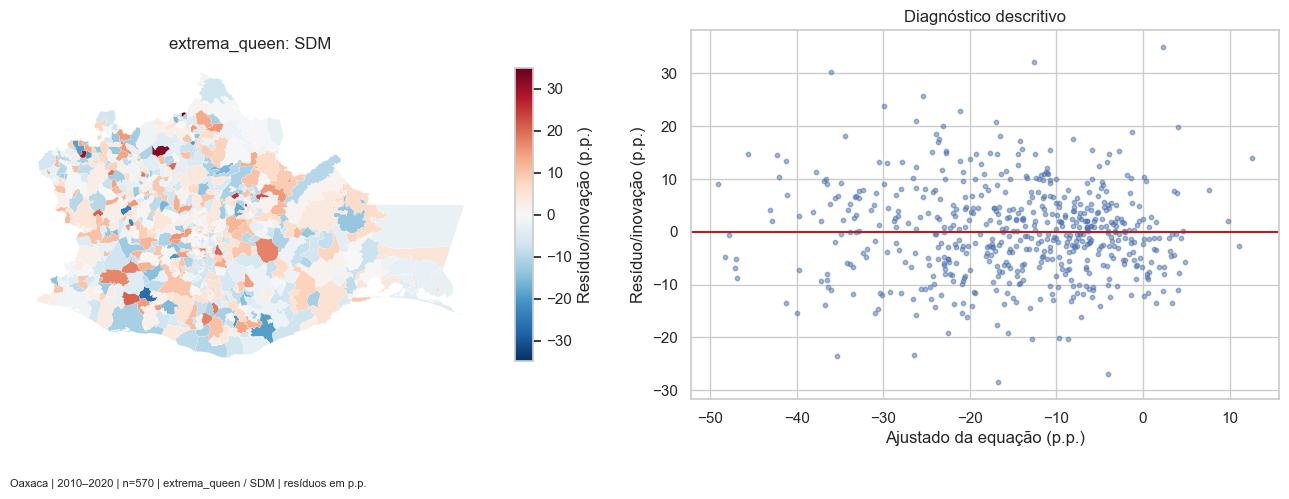

In [33]:
# Selecionando os resíduos da equação na ordem municipal
r = residuos.loc[residuos.analise.eq('extrema_queen') & residuos.modelo.eq('SDM')]
mapa_residuos['residuo'] = r.residuo_diagnostico.to_numpy()
# Centrando a escala de cores em zero
limite = r.residuo_diagnostico.abs().max()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mapa_residuos.plot(ax=axes[0], vmin=-limite, vmax=limite, **estilo_residuo)
axes[0].set_title('extrema_queen: SDM')
axes[0].set_axis_off()
# Comparando a dispersão residual com os valores ajustados
axes[1].scatter(r.ajustado_equacao, r.residuo_diagnostico, s=10, alpha=.5)
axes[1].axhline(0, color='firebrick')
axes[1].set(**estilo_ajuste)
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | 2010–2020 | n=570 | extrema_queen / SDM | resíduos em p.p.', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'residuos_extrema_queen_sdm.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran dos resíduos é −0,1762 e o AK rejeita ausência de dependência residual (*p* = 0,0132). O mapa mostra erros de ambos os sinais, entre −28,42 e +34,98 p.p. A nuvem dos ajustados ajuda a localizar esses desvios, enquanto o teste examina a dependência no conjunto.

O ponto estimado de rho é 0,8314, mas o diagnóstico residual limita a leitura de H3. O fator comum (*p* = 0,4265) permite examinar o SEM na mesma amostra. Os dois resultados de teste dizem respeito a hipóteses distintas.

### 6.2 extrema_queen / SEM

O mapa usa escala simétrica centrada em zero: as cores representam o sinal e a magnitude dos resíduos ou inovações, em p.p. O gráfico à direita permite observar dispersão e valores extremos em relação ao ajuste da equação. Essa inspeção é descritiva e deve ser combinada com os diagnósticos apresentados.

Para o SEM, os pontos e as cores representam as inovações após a filtragem espacial. No painel de dispersão, a referência horizontal marca zero. Compare os padrões em torno dessa linha e use os valores das legendas ao cotejar o SEM com o SDM.

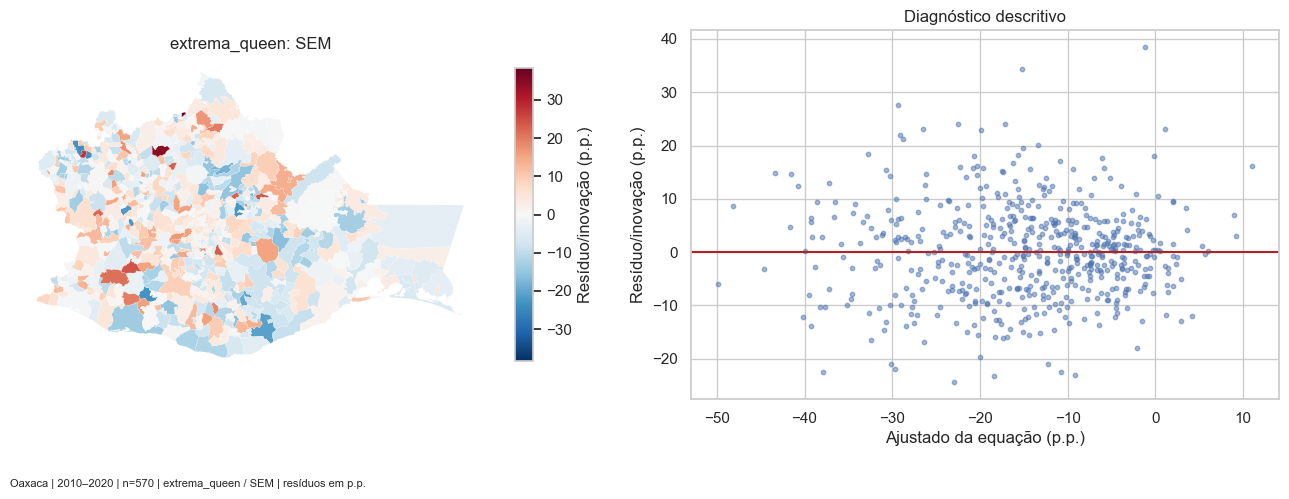

In [34]:
# Selecionando as inovações filtradas do SEM
r = residuos.loc[residuos.analise.eq('extrema_queen') & residuos.modelo.eq('SEM')]
mapa_residuos['residuo'] = r.residuo_diagnostico.to_numpy()
# Centrando a escala de cores em zero
limite = r.residuo_diagnostico.abs().max()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mapa_residuos.plot(ax=axes[0], vmin=-limite, vmax=limite, **estilo_residuo)
axes[0].set_title('extrema_queen: SEM')
axes[0].set_axis_off()
# Comparando a dispersão residual com os valores ajustados
axes[1].scatter(r.ajustado_equacao, r.residuo_diagnostico, s=10, alpha=.5)
axes[1].axhline(0, color='firebrick')
axes[1].set(**estilo_ajuste)
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | 2010–2020 | n=570 | extrema_queen / SEM | resíduos em p.p.', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'residuos_extrema_queen_sem.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** As inovações ficam distribuídas dos dois lados de zero, com mediana próxima de zero e casos acima de 38 p.p. O Moran de −0,0153 indica pouca associação espacial na estatística descritiva. A avaliação pós-GMM nesta implementação termina nesse diagnóstico descritivo.

O coeficiente de pobreza inicial de −0,5351 (IC95% [−0,6026 a −0,4677]) é compatível com convergência condicional. Lambda de 0,3555 descreve a estrutura do erro. O SEM e o SDM representam mecanismos diferentes e são comparados pelos resultados e seus limites.

### 6.3 extrema_knn5 / SDM

O mapa usa escala simétrica centrada em zero: as cores representam o sinal e a magnitude dos resíduos ou inovações, em p.p. O gráfico à direita permite observar dispersão e valores extremos em relação ao ajuste da equação. Essa inspeção é descritiva e deve ser combinada com os diagnósticos apresentados.

Representamos os resíduos da equação e os ajustados da tentativa KNN-5 para documentar seu comportamento. A figura usa a mesma estrutura dos demais diagnósticos e conserva a escala própria dos resíduos. Sua leitura deve considerar a inadmissibilidade do parâmetro espacial.

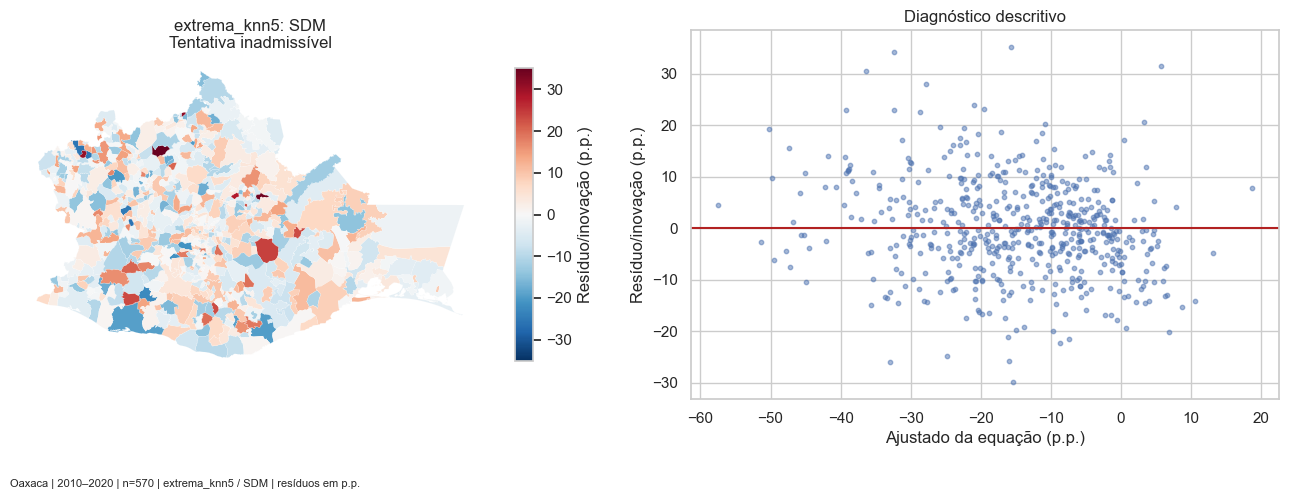

In [35]:
# Selecionando os resíduos da equação na ordem municipal
r = residuos.loc[residuos.analise.eq('extrema_knn5') & residuos.modelo.eq('SDM')]
mapa_residuos['residuo'] = r.residuo_diagnostico.to_numpy()
# Centrando a escala de cores em zero
limite = r.residuo_diagnostico.abs().max()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mapa_residuos.plot(ax=axes[0], vmin=-limite, vmax=limite, **estilo_residuo)
axes[0].set_title('extrema_knn5: SDM\nTentativa inadmissível')
axes[0].set_axis_off()
# Comparando a dispersão residual com os valores ajustados
axes[1].scatter(r.ajustado_equacao, r.residuo_diagnostico, s=10, alpha=.5)
axes[1].axhline(0, color='firebrick')
axes[1].set(**estilo_ajuste)
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | 2010–2020 | n=570 | extrema_knn5 / SDM | resíduos em p.p.', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'residuos_extrema_knn5_sdm.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** Os resíduos da tentativa variam de −29,82 a +35,21 p.p. e o gráfico de ajustados mostra o ajuste da equação. Rho de 1,2758 fica fora da faixa estável adotada. Por isso, o projeto conserva o gráfico como diagnóstico da tentativa e deixa os impactos dessa combinação em branco.

O R² parcial da primeira etapa foi 0,0523 e Wald/q foi 4,62. Em conjunto com rho, esses resultados limitam a leitura da robustez a KNN-5. A figura documenta essa sensibilidade na mesma amostra usada pela Queen.

### 6.4 total_queen / SDM

O mapa usa escala simétrica centrada em zero: as cores representam o sinal e a magnitude dos resíduos ou inovações, em p.p. O gráfico à direita permite observar dispersão e valores extremos em relação ao ajuste da equação. Essa inspeção é descritiva e deve ser combinada com os diagnósticos apresentados.

Os dois painéis se referem à mudança da pobreza total. A variável inicial desta estimação é a taxa de pobreza total de 2010. A escala da esquerda é em p.p. do desfecho e a direita permite observar a dispersão do erro ao longo dos valores ajustados.

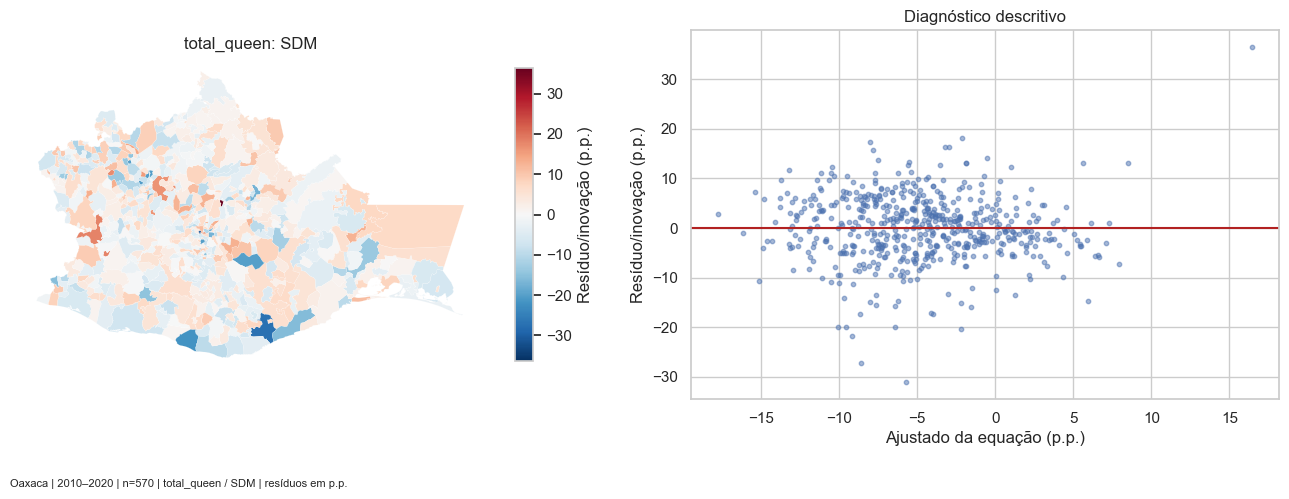

In [36]:
# Selecionando os resíduos da equação na ordem municipal
r = residuos.loc[residuos.analise.eq('total_queen') & residuos.modelo.eq('SDM')]
mapa_residuos['residuo'] = r.residuo_diagnostico.to_numpy()
# Centrando a escala de cores em zero
limite = r.residuo_diagnostico.abs().max()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mapa_residuos.plot(ax=axes[0], vmin=-limite, vmax=limite, **estilo_residuo)
axes[0].set_title('total_queen: SDM')
axes[0].set_axis_off()
# Comparando a dispersão residual com os valores ajustados
axes[1].scatter(r.ajustado_equacao, r.residuo_diagnostico, s=10, alpha=.5)
axes[1].axhline(0, color='firebrick')
axes[1].set(**estilo_ajuste)
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | 2010–2020 | n=570 | total_queen / SDM | resíduos em p.p.', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'residuos_total_queen_sdm.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O SDM para pobreza total apresenta Moran residual de −0,0937. O mapa e a nuvem mostram erros de ambos os sinais, com desvios que vão de −31,01 a +36,44 p.p. O AK não rejeita ausência de dependência residual a 5% (*p* = 0,1985), dadas as condições do teste.

O fator comum é rejeitado (*p* = 0,000928), uma diferença em relação à pobreza extrema. Essa comparação diz respeito ao desfecho e à condição inicial de pobreza total e deve ser lida junto à incerteza dos impactos.

## 7. Comparação — extrema_queen / SDM

Selecionamos a condição inicial correspondente ao desfecho e imprimimos as mesmas medidas de tamanho amostral, admissibilidade, ajuste e efeitos. As unidades da associação inicial são p.p. da mudança por p.p. da taxa em 2010. A igualdade da amostra permite concentrar a comparação na especificação e no desfecho.

In [37]:
# Selecionando os impactos da condição inicial desta especificação
efeitos_inicial = impactos.loc[impactos.analise.eq('extrema_queen') & impactos.modelo.eq('SDM') &
    impactos.variavel.eq('pepov_10')].set_index('efeito')
efeitos_inicial = efeitos_inicial.reindex(['direto', 'indireto', 'total'])
campos_efeito = ['impacto', 'ic95_inferior', 'ic95_superior']
colunas_efeito = pd.MultiIndex.from_product([['direto', 'indireto', 'total'], campos_efeito]).map('_'.join)
linha = {'analise': 'extrema_queen', 'modelo': 'SDM', 'n': sdm_extrema_queen.n, 'admissivel': abs(float(sdm_extrema_queen.rho.item())) < 1,
    'estimador': 'MQ2E White', 'pseudo_r2': sdm_extrema_queen.pr2}
linha.update(dict(zip(colunas_efeito, efeitos_inicial[campos_efeito].to_numpy().ravel())))
linhas_comparacao.append(linha)
print('extrema_queen / SDM | municípios:', sdm_extrema_queen.n)
print('Admissibilidade:', abs(float(sdm_extrema_queen.rho.item())) < 1, '| pseudo-R² descritivo:', sdm_extrema_queen.pr2)
print('Associação direta:', linha['direto_impacto'], '| IC95%:',
    linha['direto_ic95_inferior'], linha['direto_ic95_superior'])
print('Associação indireta:', linha['indireto_impacto'], '| IC95%:',
    linha['indireto_ic95_inferior'], linha['indireto_ic95_superior'])

extrema_queen / SDM | municípios: 570
Admissibilidade: True | pseudo-R² descritivo: 0.6222957461251908
Associação direta: -0.5988895860238549 | IC95%: -0.6782828260943367 -0.5194963459533731
Associação indireta: 0.5880373159916606 | IC95%: -0.7784827618893507 1.9545573938726721


**Leitura da comparação SDM extrema/Queen.** O impacto direto da taxa inicial é negativo com intervalo abaixo de zero. O indireto tem intervalo amplo que inclui zero. O ajuste descreve uma associação local consistente com H1, mas a leitura de H2 e H3 é limitada pelo AK adverso e pela incerteza do transbordamento. O pseudo-R² é uma medida descritiva da correlação entre ajustados e observados.

## 7. Comparação — extrema_queen / SEM

Selecionamos a condição inicial correspondente ao desfecho e imprimimos as mesmas medidas de tamanho amostral, admissibilidade, ajuste e efeitos. As unidades da associação inicial são p.p. da mudança por p.p. da taxa em 2010. A igualdade da amostra permite concentrar a comparação na especificação e no desfecho.

In [38]:
# Selecionando os impactos da condição inicial desta especificação
efeitos_inicial = impactos.loc[impactos.analise.eq('extrema_queen') & impactos.modelo.eq('SEM') &
    impactos.variavel.eq('pepov_10')].set_index('efeito')
efeitos_inicial = efeitos_inicial.reindex(['direto', 'indireto', 'total'])
campos_efeito = ['impacto', 'ic95_inferior', 'ic95_superior']
colunas_efeito = pd.MultiIndex.from_product([['direto', 'indireto', 'total'], campos_efeito]).map('_'.join)
linha = {'analise': 'extrema_queen', 'modelo': 'SEM', 'n': sem.n, 'admissivel': True,
    'estimador': 'GMM heterocedástico', 'pseudo_r2': sem.pr2}
linha.update(dict(zip(colunas_efeito, efeitos_inicial[campos_efeito].to_numpy().ravel())))
linhas_comparacao.append(linha)
print('extrema_queen / SEM | municípios:', sem.n)
print('Admissibilidade:', True, '| pseudo-R² descritivo:', sem.pr2)
print('Associação direta:', linha['direto_impacto'], '| IC95%:',
    linha['direto_ic95_inferior'], linha['direto_ic95_superior'])
print('Associação indireta:', linha['indireto_impacto'], '| IC95%:',
    linha['indireto_ic95_inferior'], linha['indireto_ic95_superior'])

extrema_queen / SEM | municípios: 570
Admissibilidade: True | pseudo-R² descritivo: 0.5769327060807455
Associação direta: -0.5351430898742865 | IC95%: -0.6026077866566634 -0.4676783930919096
Associação indireta: nan | IC95%: nan nan


**Leitura da comparação SEM extrema/Queen.** O coeficiente local inicial também fica abaixo de zero e em magnitude próxima à associação direta do SDM. A concordância no sinal apoia a leitura associativa de convergência condicional. O diagnóstico das inovações é descritivo. A comparação considera os dois modelos e seus mecanismos distintos.

## 7. Comparação — extrema_knn5 / SDM

Selecionamos a condição inicial correspondente ao desfecho e imprimimos as mesmas medidas de tamanho amostral, admissibilidade, ajuste e efeitos. As unidades da associação inicial são p.p. da mudança por p.p. da taxa em 2010. A igualdade da amostra permite concentrar a comparação na especificação e no desfecho.

In [39]:
# Selecionando os impactos da condição inicial desta especificação
efeitos_inicial = impactos.loc[impactos.analise.eq('extrema_knn5') & impactos.modelo.eq('SDM') &
    impactos.variavel.eq('pepov_10')].set_index('efeito')
efeitos_inicial = efeitos_inicial.reindex(['direto', 'indireto', 'total'])
campos_efeito = ['impacto', 'ic95_inferior', 'ic95_superior']
colunas_efeito = pd.MultiIndex.from_product([['direto', 'indireto', 'total'], campos_efeito]).map('_'.join)
linha = {'analise': 'extrema_knn5', 'modelo': 'SDM', 'n': sdm_extrema_knn5.n, 'admissivel': abs(float(sdm_extrema_knn5.rho.item())) < 1,
    'estimador': 'MQ2E White', 'pseudo_r2': sdm_extrema_knn5.pr2}
linha.update(dict(zip(colunas_efeito, efeitos_inicial[campos_efeito].to_numpy().ravel())))
linhas_comparacao.append(linha)
print('extrema_knn5 / SDM | municípios:', sdm_extrema_knn5.n)
print('Admissibilidade:', abs(float(sdm_extrema_knn5.rho.item())) < 1, '| pseudo-R² descritivo:', sdm_extrema_knn5.pr2)
print('Associação direta:', linha['direto_impacto'], '| IC95%:',
    linha['direto_ic95_inferior'], linha['direto_ic95_superior'])
print('Associação indireta:', linha['indireto_impacto'], '| IC95%:',
    linha['indireto_ic95_inferior'], linha['indireto_ic95_superior'])

extrema_knn5 / SDM | municípios: 570
Admissibilidade: False | pseudo-R² descritivo: 0.5737839742684084
Associação direta: nan | IC95%: nan nan
Associação indireta: nan | IC95%: nan nan


**Leitura da comparação KNN-5.** O parâmetro espacial inadmissível impede calcular impactos estáveis. Os campos ausentes permanecem identificados como tal no arquivo de comparação. O pseudo-R² dessa tentativa descreve o ajuste da equação e deve ser lido junto ao problema de admissibilidade.

## 7. Comparação — total_queen / SDM

Selecionamos a condição inicial correspondente ao desfecho e imprimimos as mesmas medidas de tamanho amostral, admissibilidade, ajuste e efeitos. As unidades da associação inicial são p.p. da mudança por p.p. da taxa em 2010. A igualdade da amostra permite concentrar a comparação na especificação e no desfecho.

In [40]:
# Selecionando os impactos da condição inicial desta especificação
efeitos_inicial = impactos.loc[impactos.analise.eq('total_queen') & impactos.modelo.eq('SDM') &
    impactos.variavel.eq('ppov_10')].set_index('efeito')
efeitos_inicial = efeitos_inicial.reindex(['direto', 'indireto', 'total'])
campos_efeito = ['impacto', 'ic95_inferior', 'ic95_superior']
colunas_efeito = pd.MultiIndex.from_product([['direto', 'indireto', 'total'], campos_efeito]).map('_'.join)
linha = {'analise': 'total_queen', 'modelo': 'SDM', 'n': sdm_total_queen.n, 'admissivel': abs(float(sdm_total_queen.rho.item())) < 1,
    'estimador': 'MQ2E White', 'pseudo_r2': sdm_total_queen.pr2}
linha.update(dict(zip(colunas_efeito, efeitos_inicial[campos_efeito].to_numpy().ravel())))
linhas_comparacao.append(linha)
print('total_queen / SDM | municípios:', sdm_total_queen.n)
print('Admissibilidade:', abs(float(sdm_total_queen.rho.item())) < 1, '| pseudo-R² descritivo:', sdm_total_queen.pr2)
print('Associação direta:', linha['direto_impacto'], '| IC95%:',
    linha['direto_ic95_inferior'], linha['direto_ic95_superior'])
print('Associação indireta:', linha['indireto_impacto'], '| IC95%:',
    linha['indireto_ic95_inferior'], linha['indireto_ic95_superior'])

total_queen / SDM | municípios: 570
Admissibilidade: True | pseudo-R² descritivo: 0.3257155970272558
Associação direta: -0.3565681613665865 | IC95%: -0.5143858247818627 -0.19875049795131025
Associação indireta: 0.5483451782527764 | IC95%: 0.2539752913776195 0.8427150651279334


**Leitura da comparação de pobreza total.** O impacto direto inicial é negativo e o indireto é positivo, com intervalo acima de zero. A diferença frente à pobreza extrema mostra que a relação espacial depende do conceito de pobreza analisado. AK e fator comum têm resultados distintos dos obtidos para o desfecho principal.

### 7. Registro da comparação

O CSV reúne as quatro especificações na mesma ordem das figuras. As ausências preservam a distinção entre resultado não aplicável e tentativa com rho inadmissível.

In [41]:
# Gravando a comparação das robustezes com os mesmos campos de referência
comparacao = pd.DataFrame(linhas_comparacao)
comparacao.to_csv(tabelas / 'comparacao_robustezes.csv', index=False, encoding='utf-8-sig')
print('Especificações comparadas:', len(comparacao))

Especificações comparadas: 4


### 7.1 Impacto direto da pobreza inicial

O ponto mostra a associação direta e a barra seu IC de 95%. Uma barra inteiramente abaixo de zero é compatível com maior redução posterior nos municípios inicialmente mais pobres, condicionada ao modelo. A ausência de ponto na KNN registra um impacto não calculável, e não um efeito igual a zero.

Nos SDM admissíveis, o ponto usa o impacto direto completo com incerteza pelo método delta. No SEM, usa a associação local estimada por GMM. A linha vertical em zero é a referência de ausência de associação. Os valores estão em p.p. da mudança por p.p. de pobreza inicial.

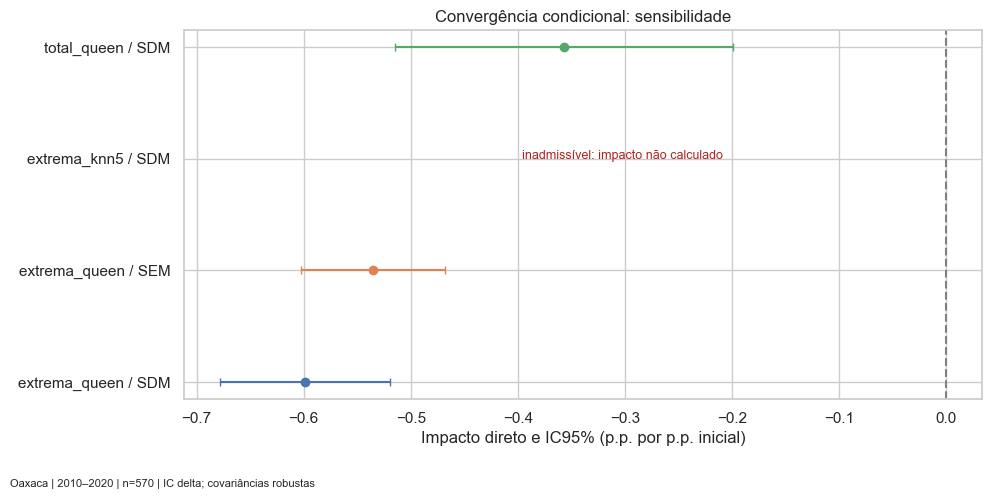

In [42]:
# Comparando as associações diretas admissíveis em uma escala comum
fig, ax = plt.subplots(figsize=(10, 5))
# Desenhando a associação direta e seu intervalo na posição 0
linha = comparacao.iloc[0]
valor, li, ls = linha.direto_impacto, linha.direto_ic95_inferior, linha.direto_ic95_superior
ax.errorbar(valor, 0, xerr=[[valor - li], [ls - valor]], fmt='o', capsize=3)

# Desenhando a associação direta e seu intervalo na posição 1
linha = comparacao.iloc[1]
valor, li, ls = linha.direto_impacto, linha.direto_ic95_inferior, linha.direto_ic95_superior
ax.errorbar(valor, 1, xerr=[[valor - li], [ls - valor]], fmt='o', capsize=3)

# Identificando a tentativa KNN sem um impacto calculável
ax.text(.55, 2, 'inadmissível: impacto não calculado', transform=ax.get_yaxis_transform(),
    ha='center', fontsize=9, color='firebrick')

# Desenhando a associação direta da pobreza total
linha = comparacao.iloc[3]
valor, li, ls = linha.direto_impacto, linha.direto_ic95_inferior, linha.direto_ic95_superior
ax.errorbar(valor, 3, xerr=[[valor - li], [ls - valor]], fmt='o', capsize=3)
ax.set_yticks(range(len(comparacao)), comparacao.analise + ' / ' + comparacao.modelo)
ax.axvline(0, color='gray', linestyle='--')
ax.set(xlabel='Impacto direto e IC95% (p.p. por p.p. inicial)', title='Convergência condicional: sensibilidade')
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | 2010–2020 | n=570 | IC delta; covariâncias robustas', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'comparacao_impactos_diretos.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** Para a pobreza extrema com Queen, a associação direta estimada é −0,5989 no SDM (IC95% [−0,6783 a −0,5195]) e −0,5351 no SEM (IC95% [−0,6026 a −0,4677]). A pobreza total apresenta associação direta de −0,3566 no SDM. Os três intervalos ficam abaixo de zero, apoiando H1. A posição da tentativa KNN-5 registra a ausência de um impacto calculável.

H2 depende da leitura indireta, fora do gráfico. Para extrema/Queen, o intervalo do indireto inclui zero (0,5880, IC95% [−0,7785 a 1,9546]). Para total/Queen, é positivo (0,5483, IC95% [0,2540 a 0,8427]). A evidência de armadilha espacial é, assim, inconclusiva para o desfecho principal. H3 também permanece inconclusiva para pobreza extrema diante do AK adverso no SDM/Queen e da inadmissibilidade do SDM/KNN-5.

### 7.2 Conferência do núcleo antes das extensões

Antes de avançar, verificamos que os dados e W estão alinhados e que direto mais indireto coincide com total nos SDM admissíveis. As três análises têm os mesmos 570 municípios. Não há comparação adicional por composição a fazer nesta base; uma mudança de cobertura foi bloqueada na leitura.

Concluir a execução não significa aprovar todos os modelos: a inadmissibilidade e as limitações de inferência continuam nos resultados. Não exportamos um CSV para cada asserção técnica.

A verificação reconcilia a ordem dos municípios nas duas matrizes, a finitude dos coeficientes e a decomposição direto mais indireto. Ela delimita o fim do núcleo antes da estimação por regimes e da avaliação de dispersão e instrumentos.

In [43]:
# Conferindo a ordem municipal e a decomposição dos impactos antes das extensões
assert queen.id_order == knn.id_order == extrema.mun.tolist()
pivo = impactos.pivot(index=['analise', 'modelo', 'variavel'], columns='efeito', values='impacto').dropna()
assert np.allclose(pivo.direto + pivo.indireto, pivo.total)
assert np.isfinite(coeficientes.coeficiente).all()
print('Núcleo executado e conferido; resultados adversos mantidos. Prosseguimos às extensões.')

Núcleo executado e conferido; resultados adversos mantidos. Prosseguimos às extensões.


**Leitura da conferência do núcleo.** Dados e pesos estão alinhados e os impactos dos SDM admissíveis respeitam a identidade direto mais indireto igual a total. Os três cenários usam a mesma amostra. As extensões seguintes examinam heterogeneidade entre regimes, dispersão entre anos e viabilidade de instrumentação.

## 8. Preparação dos regimes de língua indígena

O grupo 1 tem pelo menos 50% de falantes de língua indígena entre as pessoas de cinco anos ou mais. Mantemos a rede Queen completa. WX é calculado antes das interações com o grupo receptor, de forma que as ligações entre grupos participam dos modelos.

In [44]:
# Construindo os regressores e as interações na rede completa
r = extrema.regime_indigena.to_numpy().reshape(-1, 1)
wx = queen.sparse @ x_extrema
tamanhos = extrema.groupby('regime_indigena').size()
assert set(tamanhos.index) == {0, 1} and tamanhos.min() > 2 * (len(nomes_extrema) + 1)
locais_sdm = [*nomes_extrema, *('W_' + pd.Index(nomes_extrema)).tolist()]
nomes_sdm_reg = [*locais_sdm, 'regime_1', *('diferenca_' + pd.Index(locais_sdm)).tolist()]
nomes_sem_reg = [*nomes_extrema, 'regime_1', *('diferenca_' + pd.Index(nomes_extrema)).tolist()]
x_sdm_reg = np.column_stack([x_extrema, wx, r, r * x_extrema, r * wx])
x_sem_reg = np.column_stack([x_extrema, r, r * x_extrema])

# Formando os instrumentos da defasagem do desfecho na equação por regimes
w2x = queen.sparse @ wx
q_reg = np.column_stack([w2x, r * w2x])
nomes_w2 = 'W2_' + pd.Index(nomes_extrema)
nomes_q = [*nomes_w2.tolist(), *('regime_1_' + nomes_w2).tolist()]
print('Municípios no grupo 0:', tamanhos.loc[0])
print('Municípios no grupo 1:', tamanhos.loc[1])

Municípios no grupo 0: 348
Municípios no grupo 1: 222


**Leitura dos grupos.** Há 348 municípios no grupo 0 e 222 no grupo 1. O indicador e as interações permitem mudar os parâmetros locais entre esses grupos, enquanto o parâmetro espacial é comum. A classificação descreve uma característica municipal e sua população de referência.

### 8. SDM com parâmetros por regime

Estimamos por MQ2E White a equação com intercepto, controles e WX variando por grupo. Há uma única defasagem Wy, instrumentada por W²X e suas interações com o regime receptor. O resumo permite ler o grupo de referência e as diferenças em relação ao grupo 1.

In [45]:
# Estimando a equação Durbin por regimes com um único parâmetro espacial
sdm_regimes = spreg.TSLS(y_extrema, x_sdm_reg, yend=queen.sparse @ y_extrema, q=q_reg,
    w=queen, robust='white', spat_diag=True, vm=True, name_y='delta_pobreza', name_x=nomes_sdm_reg,
    name_yend=['W_delta_pobreza'], name_q=nomes_q, name_w='queen')
assert abs(float(sdm_regimes.betas[-1].item())) < 1, 'Rho por regimes inadmissível: rever os contrastes'
print(sdm_regimes.summary)

TSLS
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: TWO STAGE LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :          27
S.D. dependent var  :     14.0584                Degrees of Freedom    :         543
Pseudo R-squared    :      0.6424

White Standard Errors
------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        -9.09719         9.39109        -0.96870         0.33269
            pepov_10        -0.59144         0.04379       -13.50724         0.00000
              GRAD10  

**Leitura do SDM por regimes.** O coeficiente da pobreza inicial no grupo 0 é −0,5914. O termo de diferença é −0,1140, resultando em −0,7054 no grupo 1. A inferência conjunta e o contraste específico serão calculados com a covariância robusta completa. Esses coeficientes são parâmetros estruturais da equação com feedback.

### 8. SEM com parâmetros por regime

Estimamos o SEM heterocedástico com intercepto e regressores locais variando por grupo. O parâmetro lambda é compartilhado pela rede municipal. O resumo mostra os coeficientes de referência e os termos de diferença.

In [46]:
# Estimando o erro espacial com parâmetros locais por regime
sem_regimes = spreg.GMM_Error(y_extrema, x_sem_reg, w=queen, estimator='het',
    vm=True, hard_bound=True, name_y='delta_pobreza', name_x=nomes_sem_reg, name_w='queen')
assert queen.id_order == ids and sdm_regimes.n == sem_regimes.n == len(ids)
print(sem_regimes.summary)

GMM_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GM SPATIALLY WEIGHTED LEAST SQUARES (HET)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       queen
Dependent Variable  :delta_pobreza                Number of Observations:         570
Mean dependent var  :    -14.7828                Number of Variables   :          14
S.D. dependent var  :     14.0584                Degrees of Freedom    :         556
Pseudo R-squared    :      0.6142
N. of iterations    :           1                Step1c computed       :          No

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        -9.85340         4.46084        -2.20887         0.02718
            pepov_10 

**Leitura do SEM por regimes.** O coeficiente inicial do grupo 0 é −0,4992 e o do grupo 1 é −0,5435. A diferença estimada é −0,0444. A magnitude precisa ser confrontada com seu intervalo e com o teste conjunto, pois a existência de coeficientes distintos na parametrização admite incerteza sobre a diferença populacional.

### 8. Instrumentos de Wy na equação por regimes

Repetimos a verificação de identificação para a matriz com interações. A primeira etapa considera os instrumentos efetivamente fornecidos ao TSLS. Sua linha será acrescentada ao mesmo CSV do núcleo.

In [47]:
# Conferindo o posto das matrizes de instrumentos e regressores
h = np.asarray(sdm_regimes.h)
z = np.asarray(sdm_regimes.z)
x_exogeno = np.asarray(sdm_regimes.x)
h_padrao = h / np.linalg.norm(h, axis=0)
z_padrao = z / np.linalg.norm(z, axis=0)
assert np.linalg.matrix_rank(h_padrao) == h.shape[1]
assert np.linalg.matrix_rank(h_padrao.T @ z_padrao) == z.shape[1]

# Estimando a primeira etapa de Wy com covariância HC0
wy = sdm_regimes.yend[:, -1]
primeira = sm.OLS(wy, h).fit(cov_type='HC0')
q = h.shape[1] - x_exogeno.shape[1]
restricoes = np.zeros((q, h.shape[1]))
restricoes[:, x_exogeno.shape[1]:] = np.eye(q)
wald = primeira.wald_test(restricoes, scalar=True)
ssr_restrito = np.sum(sm.OLS(wy, x_exogeno).fit().resid ** 2)
r2_parcial = 1 - np.sum(primeira.resid ** 2) / ssr_restrito
instrumentos.append({'analise': 'extrema_queen_regimes', 'modelo': 'SDM', 'posto_h': h.shape[1],
    'posto_hz': z.shape[1], 'n_instrumentos_excluidos': q,
    'wald_robusto_excluidos': float(wald.statistic), 'wald_dividido_por_q': float(wald.statistic) / q,
    'p_valor': float(wald.pvalue), 'r2_parcial': r2_parcial,
    'instrumentos_excluidos': '; '.join(sdm_regimes.name_h[x_exogeno.shape[1]:])})
print('Instrumentos excluídos:', sdm_regimes.name_h[x_exogeno.shape[1]:])
print('Postos de H e H transposta Z:', np.linalg.matrix_rank(h_padrao), np.linalg.matrix_rank(h_padrao.T @ z_padrao))
print('Wald HC0 e p:', float(wald.statistic), float(wald.pvalue))
print('Wald dividido por q:', float(wald.statistic) / q, '| R² parcial:', r2_parcial)
instrumentos_wy = pd.DataFrame(instrumentos)
instrumentos_wy.to_csv(tabelas / 'instrumentos_wy.csv', index=False, encoding='utf-8-sig')

Instrumentos excluídos: ['W2_pepov_10', 'W2_GRAD10', 'W2_p_PIND10', 'W2_p_PHA10', 'W2_ln_ptot10', 'W2_ALTID', 'regime_1_W2_pepov_10', 'regime_1_W2_GRAD10', 'regime_1_W2_p_PIND10', 'regime_1_W2_p_PHA10', 'regime_1_W2_ln_ptot10', 'regime_1_W2_ALTID']
Postos de H e H transposta Z: 38 27
Wald HC0 e p: 68.04586567426908 7.419067651461965e-10
Wald dividido por q: 5.67048880618909 | R² parcial: 0.10979350495485352


**Leitura da primeira etapa por regimes.** Os postos são suficientes e o R² parcial é 0.1098, com Wald/q de 5.67. A nova matriz tem mais regressores e instrumentos que o núcleo. A contribuição condicional dos instrumentos precisa ser avaliada nessa parametrização própria, junto às condições de exogeneidade.

### 8. Wald e contraste da pobreza inicial — SDM

O teste específico avalia a diferença do coeficiente inicial entre os grupos. O Wald conjunto avalia simultaneamente o indicador e todas as interações. Usamos a covariância completa de cada estimador. No SDM, esse contraste é de parâmetros estruturais e deve ser distinguido de uma diferença completa de impactos por grupo.

In [48]:
# Selecionando a pobreza inicial e sua interação na covariância completa
beta = sdm_regimes.betas.ravel()
vm = np.asarray(sdm_regimes.vm)
rotulos = pd.Index(sdm_regimes.output.var_names)
ib = rotulos.get_loc('pepov_10')
idif = rotulos.get_loc('diferenca_pepov_10')
diferenca = beta[idif]
erro_diferenca = np.sqrt(vm[idif, idif])
indices = np.flatnonzero((rotulos == 'regime_1') | rotulos.str.startswith('diferenca_'))

# Testando conjuntamente o indicador de regime e todas as interações
restricoes = beta[indices]
cov_restricoes = vm[np.ix_(indices, indices)]
wald = float(restricoes @ linalg.solve(cov_restricoes, restricoes, assume_a='sym'))
p_h4 = 2 * stats.norm.sf(abs(diferenca / erro_diferenca))
p_conjunto = stats.chi2.sf(wald, len(indices))
h4.append({'modelo': 'SDM', 'beta_regime_0': beta[ib], 'beta_regime_1': beta[ib] + diferenca,
    'diferenca_beta_1_menos_0': diferenca, 'erro_padrao_diferenca': erro_diferenca,
    'ic95_inferior': diferenca - 1.959963984540054 * erro_diferenca,
    'ic95_superior': diferenca + 1.959963984540054 * erro_diferenca,
    'p_h4_beta': p_h4, 'wald_chow_conjunto': wald, 'p_chow_conjunto': p_conjunto, 'gl_chow': len(indices)})

# Guardando os coeficientes e imprimindo os contrastes substantivos
erros = np.sqrt(np.diag(vm))
coeficientes_regimes.append(pd.DataFrame({'modelo': 'SDM', 'variavel': rotulos,
    'coeficiente': beta, 'erro_padrao': erros, 'p_valor': 2 * stats.norm.sf(abs(beta / erros)),
    'ic95_inferior': beta - 1.959963984540054 * erros, 'ic95_superior': beta + 1.959963984540054 * erros}))
print('SDM | beta grupo 0 e grupo 1:', beta[ib], beta[ib] + diferenca)
print('Diferença grupo 1 menos grupo 0:', diferenca, '| p:', p_h4)
print('IC95% da diferença:', diferenca - 1.959963984540054 * erro_diferenca,
    diferenca + 1.959963984540054 * erro_diferenca)
print('Wald conjunto, graus de liberdade e p:', wald, len(indices), p_conjunto)

SDM | beta grupo 0 e grupo 1: -0.5914388323461743 -0.7053898360566646
Diferença grupo 1 menos grupo 0: -0.11395100371049027 | p: 0.13495176351513713
IC95% da diferença: -0.2633565063997769 0.03545449897879635
Wald conjunto, graus de liberdade e p: 37.32389882748953 13 0.00036852759236480814


**Leitura de H4 no SDM.** A diferença de −0,1140 tem p = 0,1350 e intervalo que inclui zero. O Wald conjunto rejeita estabilidade dos parâmetros (p = 0,000369). A heterogeneidade conjunta pode vir de outros regressores ou do intercepto, enquanto o contraste específico de convergência permanece inconclusivo.

### 8. Wald e contraste da pobreza inicial — SEM

O teste específico avalia a diferença do coeficiente inicial entre os grupos. O Wald conjunto avalia simultaneamente o indicador e todas as interações. Usamos a covariância completa de cada estimador. No SDM, esse contraste é de parâmetros estruturais e deve ser distinguido de uma diferença completa de impactos por grupo.

In [49]:
# Selecionando a pobreza inicial e sua interação na covariância completa
beta = sem_regimes.betas.ravel()
vm = np.asarray(sem_regimes.vm)
rotulos = pd.Index(sem_regimes.output.var_names)
ib = rotulos.get_loc('pepov_10')
idif = rotulos.get_loc('diferenca_pepov_10')
diferenca = beta[idif]
erro_diferenca = np.sqrt(vm[idif, idif])
indices = np.flatnonzero((rotulos == 'regime_1') | rotulos.str.startswith('diferenca_'))

# Testando conjuntamente o indicador de regime e todas as interações
restricoes = beta[indices]
cov_restricoes = vm[np.ix_(indices, indices)]
wald = float(restricoes @ linalg.solve(cov_restricoes, restricoes, assume_a='sym'))
p_h4 = 2 * stats.norm.sf(abs(diferenca / erro_diferenca))
p_conjunto = stats.chi2.sf(wald, len(indices))
h4.append({'modelo': 'SEM', 'beta_regime_0': beta[ib], 'beta_regime_1': beta[ib] + diferenca,
    'diferenca_beta_1_menos_0': diferenca, 'erro_padrao_diferenca': erro_diferenca,
    'ic95_inferior': diferenca - 1.959963984540054 * erro_diferenca,
    'ic95_superior': diferenca + 1.959963984540054 * erro_diferenca,
    'p_h4_beta': p_h4, 'wald_chow_conjunto': wald, 'p_chow_conjunto': p_conjunto, 'gl_chow': len(indices)})

# Guardando os coeficientes e imprimindo os contrastes substantivos
erros = np.sqrt(np.diag(vm))
coeficientes_regimes.append(pd.DataFrame({'modelo': 'SEM', 'variavel': rotulos,
    'coeficiente': beta, 'erro_padrao': erros, 'p_valor': 2 * stats.norm.sf(abs(beta / erros)),
    'ic95_inferior': beta - 1.959963984540054 * erros, 'ic95_superior': beta + 1.959963984540054 * erros}))
print('SEM | beta grupo 0 e grupo 1:', beta[ib], beta[ib] + diferenca)
print('Diferença grupo 1 menos grupo 0:', diferenca, '| p:', p_h4)
print('IC95% da diferença:', diferenca - 1.959963984540054 * erro_diferenca,
    diferenca + 1.959963984540054 * erro_diferenca)
print('Wald conjunto, graus de liberdade e p:', wald, len(indices), p_conjunto)

SEM | beta grupo 0 e grupo 1: -0.4991726727764749 -0.5435231550550175
Diferença grupo 1 menos grupo 0: -0.04435048227854255 | p: 0.48198643016518006
IC95% da diferença: -0.1679800638465903 0.07927909928950523
Wald conjunto, graus de liberdade e p: 38.0670957931852 7 2.942460070433893e-06


**Leitura de H4 no SEM.** A diferença de −0,0444 tem p = 0,4820 e intervalo que inclui zero. O Wald conjunto tem p aproximado de 0,00000294 e aponta heterogeneidade em algum parâmetro. Assim como no SDM, a rejeição conjunta convive com incerteza sobre a diferença específica da pobreza inicial. Os contrastes são associativos.

### 8. Exportação dos regimes

Os dois testes e os coeficientes por regimes são gravados nos mesmos arquivos de referência. As linhas identificam o estimador correspondente.

In [50]:
# Gravando os testes e coeficientes por regimes
h4 = pd.DataFrame(h4)
h4.to_csv(tabelas / 'regimes_h4.csv', index=False, encoding='utf-8-sig')
pd.concat(coeficientes_regimes).to_csv(tabelas / 'coeficientes_regimes.csv', index=False, encoding='utf-8-sig')
print('Modelos por regimes exportados:', len(h4))

Modelos por regimes exportados: 2


## 9. Sigma-convergência

Comparamos a dispersão da pobreza extrema em 2010 e 2020 nos mesmos municípios, com pesos iguais. O desvio-padrão usa ddof=1; o IQR complementa a leitura por ser menos sensível às caudas.

Queda na dispersão absoluta é sigma-convergência descritiva. Ela é diferente da associação condicional medida por beta e não resolve endogeneidade ou regressão à média. Não usamos um teste iid, pois os municípios têm dependência espacial.

O código calcula, para cada ano, a média municipal, o desvio-padrão amostral e a distância entre os quartis de 25% e 75%. Desvio-padrão e IQR estão em p.p. A queda dos dois indicadores informa se a dispersão diminuiu tanto no conjunto quanto no centro da distribuição.

In [51]:
# Comparando a dispersão dos níveis na mesma amostra municipal
valores_2010 = extrema.pepov_10
valores_2020 = extrema.pepov_20
sigma = pd.DataFrame([
    {'ano': 2010, 'n': len(valores_2010), 'media_pct': valores_2010.mean(),
     'desvio_padrao_pp': valores_2010.std(ddof=1),
     'intervalo_interquartil_pp': valores_2010.quantile(.75) - valores_2010.quantile(.25)},
    {'ano': 2020, 'n': len(valores_2020), 'media_pct': valores_2020.mean(),
     'desvio_padrao_pp': valores_2020.std(ddof=1),
     'intervalo_interquartil_pp': valores_2020.quantile(.75) - valores_2020.quantile(.25)}])
sigma.to_csv(tabelas / 'sigma_convergencia.csv', index=False, encoding='utf-8-sig')
print('2010 | desvio-padrão e IQR em p.p.:', sigma.loc[0, 'desvio_padrao_pp'], sigma.loc[0, 'intervalo_interquartil_pp'])
print('2020 | desvio-padrão e IQR em p.p.:', sigma.loc[1, 'desvio_padrao_pp'], sigma.loc[1, 'intervalo_interquartil_pp'])
print('Razão dos desvios-padrão 2020/2010:', sigma.loc[1, 'desvio_padrao_pp'] / sigma.loc[0, 'desvio_padrao_pp'])
print('Razão dos IQR 2020/2010:', sigma.loc[1, 'intervalo_interquartil_pp'] / sigma.loc[0, 'intervalo_interquartil_pp'])

2010 | desvio-padrão e IQR em p.p.: 21.287396910562446 34.625
2020 | desvio-padrão e IQR em p.p.: 16.8889573526982 25.375
Razão dos desvios-padrão 2020/2010: 0.7933782333112878
Razão dos IQR 2020/2010: 0.7328519855595668


**Leitura da sigma-convergência.** O desvio-padrão passa de 21,287 para 16,889 p.p., uma redução de 20,7%. O IQR cai de 34,625 para 25,375 p.p., ou 26,7%. As duas medidas apontam menor dispersão absoluta na mesma amostra municipal. A convergência beta investiga a relação condicional entre ponto de partida e mudança, enquanto essas estatísticas descrevem o conjunto das taxas.

### 9.1 Distribuição na mesma amostra

As caixas mostram o intervalo entre o primeiro e o terceiro quartil; a linha interna é a mediana. As hastes e pontos ajudam a observar as caudas. A comparação usa os mesmos 570 municípios e percentuais na mesma escala vertical.

A base é reorganizada em uma coluna de ano e outra de taxa de pobreza extrema para traçar duas caixas. A mediana é a linha interna. A altura da caixa resume a dispersão na metade central e os pontos fora das hastes ajudam a localizar observações extremas.

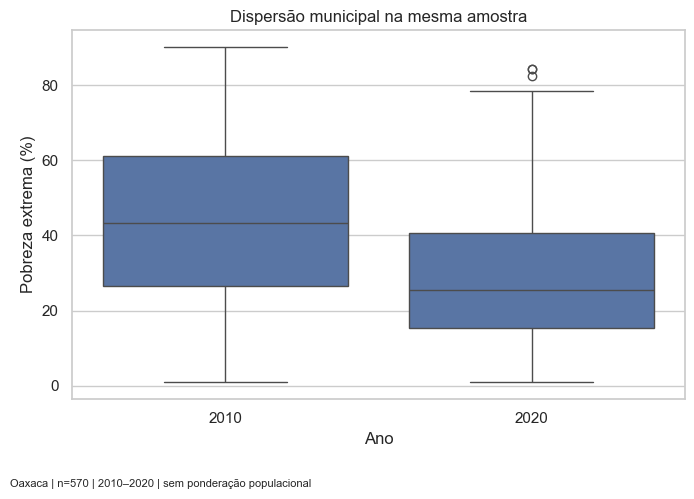

In [52]:
# Organizando as taxas de 2010 e 2020 em uma coluna para comparar os boxplots
distribuicao = extrema[['pepov_10', 'pepov_20']].rename(columns={'pepov_10': '2010', 'pepov_20': '2020'})
distribuicao = distribuicao.melt(var_name='ano', value_name='pobreza_extrema')
fig, ax = plt.subplots(figsize=(7, 5))
# Desenhando medianas e quartis na mesma escala vertical
sns.boxplot(data=distribuicao, x='ano', y='pobreza_extrema', ax=ax)
ax.set(xlabel='Ano', ylabel='Pobreza extrema (%)', title='Dispersão municipal na mesma amostra')
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | 2010–2020 | sem ponderação populacional', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'sigma_convergencia_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O boxplot de 2020 tem mediana mais baixa, de 25,5%, ante 43,4% em 2010. A caixa também é mais curta. O intervalo interquartil passou de 34,625 para 25,375 p.p., uma queda de 26,7%, enquanto o desvio-padrão caiu de 21,287 para 16,889 p.p., ou 20,7%.

A queda simultânea das duas medidas mostra sigma-convergência absoluta na mesma amostra, com municípios ainda em níveis elevados em 2020. Essa leitura descreve a distribuição. A convergência beta condicional responde à pergunta sobre a associação entre nível inicial e mudança, dados os controles.

## 10. Instrumentos de 2000 e viabilidade

Os candidatos são analfabetismo, eletricidade e piso diferente de terra. Imprimimos cobertura, mínimo e máximo na ordem dos três nomes. O CSV registra também o canal direto plausível de cada candidato.

Capital humano, infraestrutura e riqueza persistentes podem influenciar a mudança posterior por canais próprios. A procedência temporal de 2000 deixa essa questão substantiva em aberto. A etapa seguinte mede relevância condicional para a pobreza inicial e deve ser lida junto à justificativa de exclusão.

In [53]:
# Registrando a disponibilidade e os canais diretos dos candidatos de 2000
candidatos = ['p_P15AN00', 'p_ELEC00', 'p_NODIR00']
viabilidade = pd.DataFrame({'instrumento_candidato': candidatos, 'ano': 2000,
    'n_finitos': np.isfinite(dados[candidatos]).sum().to_numpy(),
    'minimo': dados[candidatos].min().to_numpy(), 'maximo': dados[candidatos].max().to_numpy(),
    'canal_direto_plausivel': [
        'capital humano persistente pode afetar diretamente a mudança posterior',
        'eletricidade pode afetar produtividade e serviços além da pobreza inicial',
        'moradia e riqueza persistentes podem afetar diretamente a trajetória posterior'],
    'decisao': 'não estimar IV: exclusão sem sustentação com os inputs disponíveis'})
viabilidade.to_csv(tabelas / 'viabilidade_instrumentos_2000.csv', index=False, encoding='utf-8-sig')
print('Candidatos:', candidatos)
print('Registros finitos na mesma ordem:', np.isfinite(dados[candidatos]).sum().to_numpy())
print('Mínimos em %:', dados[candidatos].min().to_numpy())
print('Máximos em %:', dados[candidatos].max().to_numpy())
print('Canais diretos plausíveis: capital humano, infraestrutura e riqueza persistentes')

Candidatos: ['p_P15AN00', 'p_ELEC00', 'p_NODIR00']
Registros finitos na mesma ordem: [570 570 570]
Mínimos em %: [2.3923445  1.17233294 2.77777778]
Máximos em %: [ 74.87906012 100.          97.24184326]
Canais diretos plausíveis: capital humano, infraestrutura e riqueza persistentes


**Leitura da viabilidade.** Os três candidatos têm cobertura para os 570 municípios e variam na amostra. Os conceitos de analfabetismo, eletricidade e qualidade da moradia admitem efeitos persistentes sobre a trajetória posterior por canais próprios. A precedência temporal em 2000 deixa esses canais em aberto, e a exclusão carece de sustentação substantiva com os dados disponíveis.

### 10.1 Relevância dos candidatos

Acrescentamos os três indicadores de 2000 aos controles de 2010 para explicar pepov_10. O Wald HC0 testa se seus coeficientes são conjuntamente zero. O R² parcial compara as somas de quadrados dos resíduos com e sem esse bloco na mesma amostra.

O console identifica o tamanho da amostra, o Wald, seu p-valor e o R² parcial. A indicação explícita de execução da segunda etapa registra até onde a avaliação instrumental avançou. A leitura combina relevância estatística e canais diretos plausíveis.

In [54]:
# Selecionando os municípios com dados completos para a primeira etapa diagnóstica
base_iv = dados.loc[np.isfinite(dados[['pepov_10', *controles, *candidatos]]).all(axis=1)]
incluidos = sm.add_constant(base_iv[controles], has_constant='add').to_numpy()
h_iv = np.column_stack([incluidos, base_iv[candidatos].to_numpy()])
assert np.linalg.matrix_rank(h_iv / np.linalg.norm(h_iv, axis=0)) == h_iv.shape[1]
primeira_iv = sm.OLS(base_iv.pepov_10.to_numpy(), h_iv).fit(cov_type='HC0')
# Testando conjuntamente os três candidatos com covariância HC0
restricoes = np.zeros((3, h_iv.shape[1]))
restricoes[:, -3:] = np.eye(3)
wald_iv = primeira_iv.wald_test(restricoes, scalar=True)
# Medindo o ganho de ajuste associado ao bloco de candidatos
ssr_restrito = np.sum(sm.OLS(base_iv.pepov_10.to_numpy(), incluidos).fit().resid ** 2)
relevancia_iv = pd.DataFrame([{'n': len(base_iv), 'wald_HC0': float(wald_iv.statistic),
    'p_valor': float(wald_iv.pvalue), 'gl': 3, 'wald_dividido_por_q': float(wald_iv.statistic) / 3,
    'r2_parcial': 1 - np.sum(primeira_iv.resid ** 2) / ssr_restrito, 'segunda_etapa_executada': False}])
relevancia_iv.to_csv(tabelas / 'relevancia_instrumentos_2000.csv', index=False, encoding='utf-8-sig')
print('Primeira etapa da pobreza inicial | observações:', len(base_iv))
print('Wald HC0 e p:', float(wald_iv.statistic), float(wald_iv.pvalue))
print('R² parcial dos candidatos:', 1 - np.sum(primeira_iv.resid ** 2) / ssr_restrito)
print('Segunda etapa IV executada:', False)

Primeira etapa da pobreza inicial | observações: 570
Wald HC0 e p: 302.1383679860333 3.4273648694992645e-65
R² parcial dos candidatos: 0.3413987633269212
Segunda etapa IV executada: False


**Conclusão da extensão instrumental.** Os 570 municípios têm os três candidatos. Wald HC0=302,138 e R² parcial=0,341 mostram relevância conjunta, mas os canais diretos permanecem plausíveis. A avaliação de viabilidade está concluída; a segunda etapa não foi realizada por falta de exclusão defensável. Portanto, não há uma estimativa IV válida para comparar com o núcleo.

## 11. Encerramento e preservação

As exportações ficam agrupadas por assunto, com análise e modelo identificados nas próprias tabelas. Foram mantidos resultados substantivos, auditoria e rastreabilidade; foram retirados CSVs de assinaturas de APIs, verificações repetidas, manifesto e sínteses que já estavam nos textos.

Por fim, conferimos os 21 inputs originais contra o registro criado no notebook 1. A execução termina com as mesmas ressalvas científicas: possível erro de medida, regressão à média, confundimento, limites dos testes e sensibilidade à especificação. A simplicidade do código não converte essas associações em efeitos causais.

A procedência exportada no primeiro notebook fornece a lista de caminhos e seus hashes esperados. A verificação recalcula o hash dos dados brutos e dos materiais de referência e confere o total de entradas e de municípios.

In [55]:
# Comparando os hashes atuais com a procedência registrada no notebook 1
procedencia = pd.read_csv(tabelas / 'procedencia_inputs.csv', dtype=str)
for _, linha in procedencia.iterrows():
    assert hashlib.sha256((raiz / linha.arquivo).read_bytes()).hexdigest() == linha.sha256
assert len(procedencia) == 21 and len(dados) == 570
print('Análises executadas; 570 municípios e 21 inputs preservados. IV não estimado por exclusão indefensável.')

Análises executadas; 570 municípios e 21 inputs preservados. IV não estimado por exclusão indefensável.
